# SOLA 4237 Assignment 2 – Household BESS Optimisation (VPP-SPREE)

In [1]:
import os, time, warnings
from dataclasses import dataclass, replace
import numpy as np
import pandas as pd
import scipy.sparse as sp
from scipy.optimize import linprog
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

DATA_CSV = "Data_VIC_Mt Buller - Alpine_2023-2024_partial.csv"
AEMO_DIR = "data/aemo"
CACHE_DIR = "data/cache"
os.makedirs(AEMO_DIR, exist_ok=True); os.makedirs(CACHE_DIR, exist_ok=True)

DT = 5 / 60          # h per interval
STEPS_PER_DAY = 288
LAT, LON = -37.146, 146.439   # Mt Buller

# Consistent categorical palette (fixed order, never cycled)
C = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", yellow="#eda100",
         magenta="#e87ba4", green="#008300", violet="#6250d6", red="#e34948", grey="#8a8985")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "lines.linewidth": 1.4,
                     "legend.frameon": False, "font.size": 10})

# Step 1 – Initial telemetry cleaning and augmenting

## 1.1 Loading data, handling of time and resampling

In [2]:
raw = pd.read_csv(DATA_CSV, parse_dates=["timestamp"]).set_index("timestamp")
raw.columns = ["irr", "temp", "pv", "pv_comm", "load", "spot", "imp_flat", "exp_flat", "imp_tou", "exp_tou"]

idx = raw.index
print("rows:", len(raw), "| duplicates:", idx.duplicated().sum(),
      "| irregular steps:", (idx.to_series().diff().dropna() != pd.Timedelta("5min")).sum())
print("range:", idx.min(), "->", idx.max())
avail = raw.groupby(raw.index.year).apply(lambda g: g.notna().mean() * 100).T.round(2)
avail.columns = [f"{c} % available" for c in avail.columns]
avail

rows: 210528 | duplicates: 0 | irregular steps: 0
range: 2023-01-01 00:00:00 -> 2024-12-31 23:55:00


,2023 % available,2024 % available
irr,99.630,99.370
temp,99.630,99.370
pv,99.630,0.000
pv_comm,0.000,100.000
load,99.630,99.370
spot,100.000,0.000
imp_flat,100.000,100.000
exp_flat,100.000,100.000
imp_tou,100.000,100.000
exp_tou,100.000,100.000


In [3]:
# Resampling rule: power (kW, interval average) is AVERAGED, energy (kWh) is SUMMED.
cols = ["load", "pv", "pv_comm"]
cnt = raw[cols].resample("h").count()
kw_h = raw[cols].resample("h").mean()                       # mean kW over the hour
kwh_h = (raw[cols] * DT).resample("h").sum(min_count=1)     # kWh in the hour
full = cnt.eq(12)                                           # hours with all twelve 5-min values
print("Hourly mean kW equals hourly kWh on complete hours:",
      bool(np.allclose(kw_h[full].fillna(0), kwh_h[full].fillna(0))))

# Time-convention check: PV-weighted centre of the day should be ~12:30 local solar noon in every month
p = raw.loc["2023", "pv"].dropna()
tod = (p.index - pd.Timedelta(minutes=2.5))
centre = (p * (tod.hour + tod.minute / 60)).groupby(p.index.month).sum() / p.groupby(p.index.month).sum()
print("PV energy centroid by month (h, AEST):", centre.round(2).to_dict())
print("-> constant all year: timestamps are fixed AEST (no DST jump in Apr/Oct).")

Hourly mean kW equals hourly kWh on complete hours: True
PV energy centroid by month (h, AEST): {1: 12.73, 2: 12.83, 3: 12.77, 4: 12.57, 5: 12.59, 6: 12.87, 7: 12.83, 8: 12.69, 9: 12.58, 10: 12.46, 11: 12.33, 12: 12.5}
-> constant all year: timestamps are fixed AEST (no DST jump in Apr/Oct).


## 1.2 Missing data – identification and cleaning

In [4]:
def gap_table(s):
    m = s.isna()
    grp = (m != m.shift()).cumsum()[m]
    runs = m[m].groupby(grp).apply(lambda x: pd.Series({"start": x.index[0], "steps": len(x)}))
    return runs.unstack() if len(runs) else pd.DataFrame(columns=["start", "steps"])

gaps = gap_table(raw["load"])
gaps["hours"] = gaps["steps"].astype(int) * 5 / 60
print(f"{len(gaps)} gaps, {gaps.steps.sum()} missing 5-min records "
      f"({gaps.steps.sum()/len(raw)*100:.2f} %)")
gaps.sort_values("steps", ascending=False).head(10)

27 gaps, 1048 missing 5-min records (0.50 %)


,start,steps,hours
load,,,
28,2024-01-12 19:35:00,288,24.000
44,2024-06-25 14:15:00,67,5.583
22,2023-10-21 00:35:00,60,5.000
10,2023-06-24 17:15:00,58,4.833
12,2023-08-18 06:15:00,58,4.833
46,2024-07-21 10:00:00,57,4.750
2,2023-02-01 15:00:00,57,4.750
48,2024-07-23 12:45:00,55,4.583
50,2024-08-09 11:15:00,48,4.000


In [5]:
def fill_profile(s, max_interp=12, window_days=3):
    s = s.copy()
    isna = s.isna()
    grp = (isna != isna.shift()).cumsum()
    run_len = isna.groupby(grp).transform("sum").where(isna, 0)
    short = isna & (run_len <= max_interp)
    interp = s.interpolate(limit_area="inside")
    s[short] = interp[short]
    # long gaps: same time-of-day mean over neighbouring days
    for t in s.index[s.isna()]:
        cands = [t + pd.Timedelta(days=d) for d in range(-window_days, window_days + 1) if d != 0]
        vals = s.reindex(cands).dropna()
        s[t] = vals.mean() if len(vals) else np.nan
    return s.fillna(0.0)

df = raw.copy()
df["filled"] = raw["load"].isna()
for col in ["irr", "temp", "load", "pv"]:
    yrs = []
    for y in (2023, 2024):
        part = df.loc[str(y), col]
        if part.notna().sum() == 0:      # pv in 2024 does not exist
            yrs.append(part); continue
        yrs.append(fill_profile(part))
    df[col] = pd.concat(yrs)
print(df[["irr", "temp", "load", "pv", "pv_comm"]].isna().groupby(df.index.year).sum())

           irr  temp  load      pv  pv_comm
timestamp                                  
2023         0     0     0       0   105120
2024         0     0     0  105408        0


## 1.3 Suspicious / spurious data

In [6]:
# spurious data checks
d23 = df.loc["2023"]
ratio = (d23.pv / (d23.irr / 1000)).where(d23.irr > 600)
print("PV>0 while irradiance=0:", int(((d23.irr == 0) & (d23.pv > 0.05)).sum()))
print("High irradiance (>600 W/m2) but PV<0.5 kW:", int(((d23.irr > 600) & (d23.pv < 0.5)).sum()))
print("PV/irradiance ratio (kW per kW/m2) quantiles:", ratio.quantile([.01, .5, .99]).round(2).to_dict())

PV>0 while irradiance=0: 0
High irradiance (>600 W/m2) but PV<0.5 kW: 0
PV/irradiance ratio (kW per kW/m2) quantiles: {0.01: 2.55, 0.5: 7.14, 0.99: 8.9}


In [7]:
def longest_run(s):
    g = (s != s.shift()).cumsum()
    return int(s.groupby(g).size().max())

checks = pd.Series({
    "load < 0 kW": int((df.load < 0).sum()),
    "load > 10 kW (above a single-phase household)": int((df.load > 10).sum()),
    "5-min load step > 2 kW": int((df.load.diff().abs() > 2).sum()),
    "longest identical load run (5-min steps)": longest_run(raw.load.dropna()),
    "PV < 0 or > 1.1 x 99.9th pct": int(((df.loc['2023','pv'] < 0) | (df.loc['2023','pv'] > 1.1 * df.loc['2023','pv'].quantile(.999))).sum()),
    "commercial PV > 0 at night (irr = 0)": int(((df.irr == 0) & (df.pv_comm > 0.05)).sum()),
    "irradiance > 1,250 W/m2": int((df.irr > 1250).sum()),
    "temperature outside -20..45 C": int(((df.temp < -20) | (df.temp > 45)).sum()),
    "spot outside NEM floor/cap (-1.0..17.5 $/kWh)": int(((df.spot < -1.0) | (df.spot > 17.5)).sum()),
}, name="count")
display(checks.to_frame())

,count
load < 0 kW,0
load > 10 kW (above a single-phase household),0
5-min load step > 2 kW,50
longest identical load run (5-min steps),9
PV < 0 or > 1.1 x 99.9th pct,11
commercial PV > 0 at night (irr = 0),0
"irradiance > 1,250 W/m2",0
temperature outside -20..45 C,0
spot outside NEM floor/cap (-1.0..17.5 $/kWh),0


## 1.4 Site load and solar analysis

,Load (kWh),PV (kWh),Mean daily load (kWh),Mean daily PV (kWh),PV / Load
timestamp,,,,,
2023,"4,486.849","11,756.340",12.293,32.209,2.620
2024,"4,495.432","12,788.990",12.283,34.943,2.845


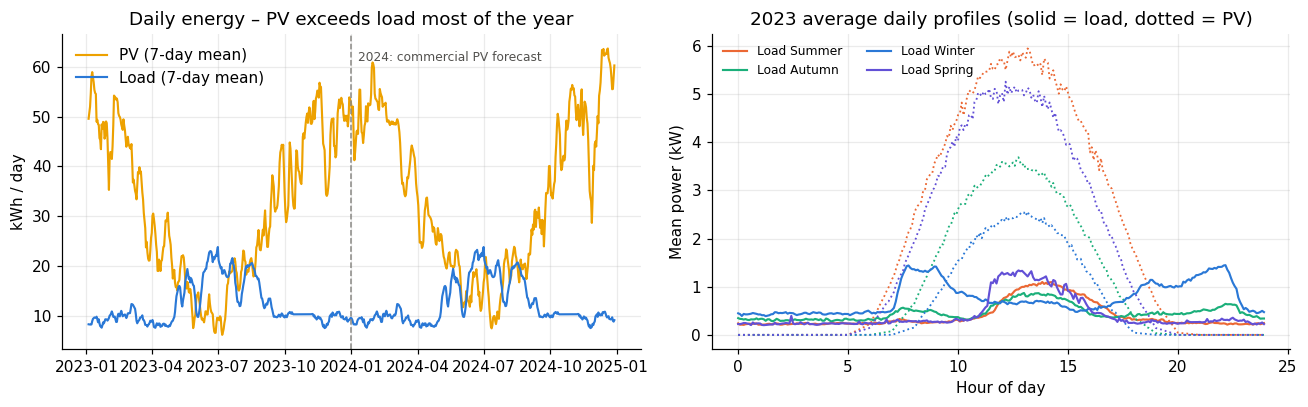

Energy consumed while PV is ~0 (2023): mean 4.5 kWh/night, P50 2.5, P90 10.5 kWh  -> indicates the useful battery energy
Load peak (5-min): 2.98 kW, 99th pct 2.17 kW -> sizing of inverter power
PV peak: 9.53 kW; implied array ≈ 10.0 kWp (AC)


In [8]:
daily = df[["load", "pv", "pv_comm", "irr"]].resample("D").sum() * DT
daily["pv_any"] = daily.pv.where(daily.index.year == 2023, daily.pv_comm)
annual = pd.DataFrame({
    "Load (kWh)": daily.load.groupby(daily.index.year).sum(),
    "PV (kWh)": daily.pv_any.groupby(daily.index.year).sum(),
    "Mean daily load (kWh)": daily.load.groupby(daily.index.year).mean(),
    "Mean daily PV (kWh)": daily.pv_any.groupby(daily.index.year).mean(),
})
annual["PV / Load"] = annual["PV (kWh)"] / annual["Load (kWh)"]
display(annual)

season = {12: "Summer", 1: "Summer", 2: "Summer", 3: "Autumn", 4: "Autumn", 5: "Autumn",
          6: "Winter", 7: "Winter", 8: "Winter", 9: "Spring", 10: "Spring", 11: "Spring"}
d = df.loc["2023"].copy()
d["season"] = d.index.month.map(season)
d["tod"] = d.index.hour + d.index.minute / 60
prof = d.groupby(["season", "tod"])[["load", "pv"]].mean()

# Report Figure 2
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
ax = axes[0]
ax.plot(daily.index, daily.pv_any.rolling(7, center=True).mean(), color=C["yellow"], label="PV (7-day mean)")
ax.plot(daily.index, daily.load.rolling(7, center=True).mean(), color=C["blue"], label="Load (7-day mean)")
ax.axvline(pd.Timestamp("2024-01-01"), color=C["grey"], ls="--", lw=1)
ax.text(pd.Timestamp("2024-01-10"), ax.get_ylim()[1] * 0.92, "2024: commercial PV forecast", fontsize=8, color="#52514e")
ax.set_ylabel("kWh / day"); ax.set_title("Daily energy – PV exceeds load most of the year"); ax.legend()
ax = axes[1]
for s_, col in zip(["Summer", "Autumn", "Winter", "Spring"], [C["orange"], C["aqua"], C["blue"], C["violet"]]):
    ax.plot(prof.loc[s_].index, prof.loc[s_, "load"], color=col, label=f"Load {s_}")
    ax.plot(prof.loc[s_].index, prof.loc[s_, "pv"], color=col, ls=":", lw=1.2)
ax.set_xlabel("Hour of day"); ax.set_ylabel("Mean power (kW)")
ax.set_title("2023 average daily profiles (solid = load, dotted = PV)"); ax.legend(fontsize=8, ncol=2)
plt.tight_layout(); plt.show()

night = d[(d.pv < 0.01)].resample("D")["load"].sum() * DT
print(f"Energy consumed while PV is ~0 (2023): mean {night.mean():.1f} kWh/night, "
      f"P50 {night.median():.1f}, P90 {night.quantile(.9):.1f} kWh  -> indicates the useful battery energy")
print(f"Load peak (5-min): {d.load.max():.2f} kW, 99th pct {d.load.quantile(.99):.2f} kW -> sizing of inverter power")
print(f"PV peak: {d.pv.max():.2f} kW; implied array ≈ {d.pv.max()/0.95:.1f} kWp (AC)")

,Mean temp (C),Min temp (C),Irradiance (kWh/m2/day),PV (kWh/day),Load (kWh/day)
season,,,,,
Summer,11.900,-0.800,7.000,48.800,9.600
Autumn,5.400,-4.600,3.500,24.700,11.100
Winter,0.700,-9.700,2.100,15.500,18.100
Spring,6.200,-5.200,5.700,40.200,10.300


2023: temp -9.7 to 25.9 C (mean 6.0); annual irradiance 1,661 kWh/m2; intervals < 0 C 18.5 %, < -5 C 0.4 %
2024: temp -9.3 to 26.2 C (mean 6.4); annual irradiance 1,760 kWh/m2; intervals < 0 C 17.9 %, < -5 C 1.2 %
Daily load vs mean temperature: r = -0.63, 0.57 kWh/day more load per 1 C colder (heating)
PV per unit irradiance: 6.92 (Jan) to 7.39 (Jun) kW per kW/m2 -> cold modules are more efficient


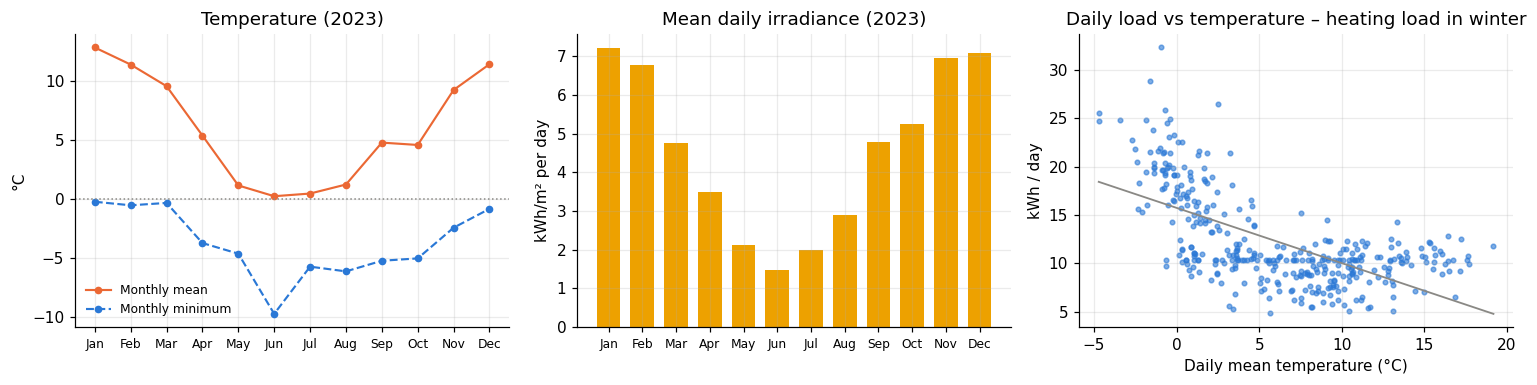

In [9]:
# Report Table 1 and Figure 1. Weather: temperature and irradiance drive both PV output and (via heating) the load
w = df.loc["2023"].copy()
dly = pd.DataFrame({"T": w.temp.resample("D").mean(), "Tmin": w.temp.resample("D").min(),
                    "Irr (kWh/m2)": w.irr.resample("D").sum() * DT / 1000,
                    "Load (kWh)": w.load.resample("D").sum() * DT, "PV (kWh)": w.pv.resample("D").sum() * DT})
dly["season"] = dly.index.month.map(season)
wtab = dly.groupby("season").agg(**{"Mean temp (C)": ("T", "mean"), "Min temp (C)": ("Tmin", "min"),
                                    "Irradiance (kWh/m2/day)": ("Irr (kWh/m2)", "mean"),
                                    "PV (kWh/day)": ("PV (kWh)", "mean"), "Load (kWh/day)": ("Load (kWh)", "mean")})
wtab = wtab.loc[["Summer", "Autumn", "Winter", "Spring"]]
display(wtab.round(1))
for y in ["2023", "2024"]:
    t = df.loc[y, "temp"]
    print(f"{y}: temp {t.min():.1f} to {t.max():.1f} C (mean {t.mean():.1f}); annual irradiance "
          f"{df.loc[y, 'irr'].sum() * DT / 1000:,.0f} kWh/m2; intervals < 0 C {100 * (t < 0).mean():.1f} %, < -5 C {100 * (t < -5).mean():.1f} %")
slope, icpt = np.polyfit(dly["T"], dly["Load (kWh)"], 1)
print(f"Daily load vs mean temperature: r = {dly['Load (kWh)'].corr(dly['T']):.2f}, "
      f"{-slope:.2f} kWh/day more load per 1 C colder (heating)")
pvr = (w.pv.resample("ME").sum() / w.irr.resample("ME").sum() * 1000)
print(f"PV per unit irradiance: {pvr.min():.2f} (Jan) to {pvr.max():.2f} (Jun) kW per kW/m2 -> cold modules are more efficient")

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
mo = dly.resample("ME").agg({"T": "mean", "Tmin": "min", "Irr (kWh/m2)": "mean"})
xm = np.arange(12); lab = mo.index.strftime("%b")
axes[0].plot(xm, mo["T"], "o-", ms=4, color=C["orange"], label="Monthly mean")
axes[0].plot(xm, mo["Tmin"], "o--", ms=4, color=C["blue"], label="Monthly minimum")
axes[0].axhline(0, color=C["grey"], lw=1, ls=":")
axes[0].set_xticks(xm, lab, fontsize=8); axes[0].set_ylabel("°C"); axes[0].set_title("Temperature (2023)"); axes[0].legend(fontsize=8)
axes[1].bar(xm, mo["Irr (kWh/m2)"], 0.7, color=C["yellow"])
axes[1].set_xticks(xm, lab, fontsize=8); axes[1].set_ylabel("kWh/m² per day"); axes[1].set_title("Mean daily irradiance (2023)")
axes[2].scatter(dly["T"], dly["Load (kWh)"], s=9, color=C["blue"], alpha=0.6)
tt = np.linspace(dly["T"].min(), dly["T"].max(), 50)
axes[2].plot(tt, slope * tt + icpt, color=C["grey"], lw=1.2)
axes[2].set_xlabel("Daily mean temperature (°C)"); axes[2].set_ylabel("kWh / day")
axes[2].set_title("Daily load vs temperature – heating load in winter")
plt.tight_layout(); plt.show()

## 1.5 Power vs energy calculations

In [10]:
d5 = df.loc["2023"]
pe = pd.DataFrame({
    "Annual energy (kWh) = sum(P) x 5/60": [d5.load.sum() * DT, d5.pv.sum() * DT],
    "Peak 5-min power (kW)": [d5.load.max(), d5.pv.max()],
    "Peak hourly-average power (kW)": [d5.load.resample("h").mean().max(), d5.pv.resample("h").mean().max()],
    "Peak daily-average power (kW)": [d5.load.resample("D").mean().max(), d5.pv.resample("D").mean().max()],
    "Mean power (kW)": [d5.load.mean(), d5.pv.mean()],
}, index=["Load", "PV"]).T
display(pe.round(2))
print(f"PV capacity factor (vs {d5.pv.quantile(.999):.2f} kW AC peak): {d5.pv.mean()/d5.pv.quantile(.999)*100:.1f} %")
print("Coarser resampling hides power peaks (kW) but preserves energy (kWh) -> the optimiser runs at 5-min resolution.")
print("Battery: capacity is energy (kWh), inverter rating is power (kW); "
      "a 5 kW set-point for one 5-min interval moves 5 x 5/60 = 0.417 kWh.")

,Load,PV
Annual energy (kWh) = sum(P) x 5/60,"4,486.850","11,756.340"
Peak 5-min power (kW),2.980,9.530
Peak hourly-average power (kW),2.730,8.080
Peak daily-average power (kW),1.350,2.750
Mean power (kW),0.510,1.340


PV capacity factor (vs 8.35 kW AC peak): 16.1 %
Coarser resampling hides power peaks (kW) but preserves energy (kWh) -> the optimiser runs at 5-min resolution.
Battery: capacity is energy (kWh), inverter rating is power (kW); a 5 kW set-point for one 5-min interval moves 5 x 5/60 = 0.417 kWh.


## 1.6 Augmenting – 2024 wholesale prices from AEMO

In [11]:
import urllib.request
def aemo_month(yyyymm, region="VIC1"):
    fn = f"{AEMO_DIR}/PRICE_AND_DEMAND_{yyyymm}_{region}.csv"
    if not os.path.exists(fn):
        url = f"https://www.aemo.com.au/aemo/data/nem/priceanddemand/PRICE_AND_DEMAND_{yyyymm}_{region}.csv"
        req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
        with urllib.request.urlopen(req, timeout=60) as r, open(fn, "wb") as f:
            f.write(r.read())
    a = pd.read_csv(fn, parse_dates=["SETTLEMENTDATE"])
    return a.set_index("SETTLEMENTDATE")["RRP"] / 1000.0   # $/MWh -> $/kWh

# validation against provided 2023 data
chk = aemo_month("202301")
common = chk.index.intersection(df.index)
print("Jan-2023 max abs diff vs provided spot ($/kWh):", float((chk[common] - df.loc[common, "spot"]).abs().max()))

months = ["202312"] + [f"2024{m:02d}" for m in range(1, 13)]
aemo = pd.concat([aemo_month(m) for m in months]).sort_index()
aemo = aemo[~aemo.index.duplicated()]
y24 = df.index[df.index.year == 2024]
df.loc[y24, "spot"] = aemo.reindex(y24).values
print("2024 spot missing after merge:", int(df.loc["2024", "spot"].isna().sum()))
df.groupby(df.index.year)["spot"].describe()

Jan-2023 max abs diff vs provided spot ($/kWh): 2.7755575615628914e-17


2024 spot missing after merge: 0


,count,mean,std,min,25%,50%,75%,max
timestamp,,,,,,,,
2023,"105,120.000",0.055,0.111,-0.996,0.002,0.054,0.099,14.522
2024,"105,408.000",0.082,0.382,-1.000,0.008,0.066,0.130,17.500


## 1.7 Augmenting – AusNet network tariff and customer price signals

In [12]:
AUSNET_NAST11 = pd.DataFrame({          # c/kWh ex GST, standing $/yr (source: AusNet schedule of tariffs)
    "valid_from": pd.to_datetime(["2022-07-01", "2023-07-01", "2024-07-01"]),
    "peak_c_kwh": [22.9085, 22.4055, 23.8012],
    "offpeak_c_kwh": [4.7720, 4.6394, 4.8280],
    "standing_$_yr": [125.07, 132.87, 138.51],
}, index=["FY2022-23", "FY2023-24", "FY2024-25"])
display(AUSNET_NAST11)

def network_charge(index):
    # Interval-ending AEST timestamps -> AusNet NAST11 network charge in $/kWh.
    mid = (index - pd.Timedelta(minutes=2.5)).tz_localize("Etc/GMT-10").tz_convert("Australia/Melbourne")
    peak = (mid.hour >= 15) & (mid.hour < 21)
    fy = np.searchsorted(AUSNET_NAST11.valid_from.values, (index - pd.Timedelta(minutes=2.5)).values, side="right") - 1
    rates = AUSNET_NAST11.iloc[fy]
    return np.where(peak, rates.peak_c_kwh.values, rates.offpeak_c_kwh.values) / 100, peak

df["net"], df["net_peak"] = network_charge(df.index)
chk = df.groupby([df.index.year, df.index.month])["net_peak"].apply(
    lambda s: f"{s[s].index.hour.min()}–{s[s].index.hour.max()+1} AEST")
print("Peak window in NEM time (AEST) by month – shifts 1 h earlier during daylight saving:")
print(chk.loc[2023].to_dict())
print("Mean network charge by year ($/kWh):", df.groupby(df.index.year)["net"].mean().round(4).to_dict())

,valid_from,peak_c_kwh,offpeak_c_kwh,standing_$_yr
FY2022-23,2022-07-01,22.909,4.772,125.070
FY2023-24,2023-07-01,22.405,4.639,132.870
FY2024-25,2024-07-01,23.801,4.828,138.510


Peak window in NEM time (AEST) by month – shifts 1 h earlier during daylight saving:
{1: '14–21 AEST', 2: '14–21 AEST', 3: '14–21 AEST', 4: '14–22 AEST', 5: '15–22 AEST', 6: '15–22 AEST', 7: '15–22 AEST', 8: '15–22 AEST', 9: '15–22 AEST', 10: '14–21 AEST', 11: '14–21 AEST', 12: '14–21 AEST'}


Mean network charge by year ($/kWh): {2023: 0.0919, 2024: 0.0933}


In [13]:
LF, ENV, MKT, HEDGE = 1.05, 0.016, 0.003, 0.010     # loss factor, certificates, market fees, hedging ($/kWh)
VPP_FEE = 25.0                                     # $/month for the optimised wholesale service
def retail_prices(spot, net):
    # Final dynamic price passed to the customer. net = AusNet NAST11 network charge ($/kWh, ex GST).
    energy = LF * spot
    p_imp = np.where(spot >= 0, 1.10 * energy, energy) + 1.10 * (net + ENV + MKT + HEDGE)
    p_exp = LF * spot
    return p_imp, p_exp

df["p_imp_ws"], df["p_exp_ws"] = retail_prices(df.spot.values, df.net.values)
print("Import price always above export price:", bool((df.p_imp_ws > df.p_exp_ws).all()))
sig = df.groupby(df.index.year)[["imp_flat", "imp_tou", "p_imp_ws", "exp_flat", "p_exp_ws"]].mean()
sig.columns = ["Flat import", "ToU import", "Wholesale import", "Flat/ToU export", "Wholesale export"]
print("Mean customer prices ($/kWh):"); display(sig.round(3))
print(f"Negative spot intervals: 2023 {(df.loc['2023','spot'] < 0).mean()*100:.1f} %, 2024 {(df.loc['2024','spot'] < 0).mean()*100:.1f} %")

Import price always above export price: True
Mean customer prices ($/kWh):


,Flat import,ToU import,Wholesale import,Flat/ToU export,Wholesale export
timestamp,,,,,
2023,0.300,0.242,0.197,0.050,0.058
2024,0.300,0.242,0.230,0.050,0.086


Negative spot intervals: 2023 21.6 %, 2024 21.1 %


# Step 2 – BESS analysis and optimisation

## 2.1 Battery model and operational constraints

In [14]:
@dataclass
class Battery:
    name: str = "13.5 kWh / 5 kW"
    e_nom: float = 13.5        # kWh nameplate
    p_max: float = 5.0         # kW charge/discharge (AC)
    soc_min: float = 0.10
    soc_max: float = 0.95
    eta_c: float = 0.97 * 0.975
    eta_d: float = 0.97 * 0.975
    c_deg: float = 0.04        # $/kWh throughput (each of charge and discharge)
    soc0: float = 0.5
    capex: float = None        # installed cost AUD
    @property
    def e_min(self): return self.soc_min * self.e_nom
    @property
    def e_max(self): return self.soc_max * self.e_nom
    @property
    def usable(self): return self.e_max - self.e_min

def charge_derate(temp):
    t = np.asarray(temp)
    return np.where(t >= 0, 1.0, np.where(t >= -5, 0.5, 0.2))

print("Round-trip efficiency:", round(Battery().eta_c * Battery().eta_d, 4))
print("Share of 2023 intervals with charge derating:",
      f"{(charge_derate(df.loc['2023','temp']) < 1).mean()*100:.1f} %")

Round-trip efficiency: 0.8944
Share of 2023 intervals with charge derating: 18.5 %


In [15]:
# System topology: existing PV inverter (measured PV is AC) + retrofit AC-coupled battery.
ETA = dict(pv_inverter=0.97, battery_inverter=0.97, cell_bms=0.975)
ac_ch = ETA["battery_inverter"] * ETA["cell_bms"]          # AC -> stored
ac_dis = ETA["cell_bms"] * ETA["battery_inverter"]         # stored -> AC
paths = pd.DataFrame({
    "AC-coupled (modelled)": {
        "PV (DC) -> load": ETA["pv_inverter"],
        "PV (DC) -> battery -> load": ETA["pv_inverter"] * ac_ch * ac_dis,
        "Grid -> battery -> load": ac_ch * ac_dis,
        "Battery round trip (AC to AC)": ac_ch * ac_dis},
})
print("Component efficiencies:", ETA)
print("End-to-end path efficiencies (energy delivered / energy in):")
display((paths * 100).round(1).astype(str) + " %")
print(f"Model parameters: eta_c = eta_d = {Battery().eta_c:.4f}; round trip {Battery().eta_c*Battery().eta_d*100:.1f} % "
      "(PV-inverter loss is already inside the measured AC PV, so it is not applied again).")

Component efficiencies: {'pv_inverter': 0.97, 'battery_inverter': 0.97, 'cell_bms': 0.975}
End-to-end path efficiencies (energy delivered / energy in):


,AC-coupled (modelled)
PV (DC) -> load,97.0 %
PV (DC) -> battery -> load,86.8 %
Grid -> battery -> load,89.4 %
Battery round trip (AC to AC),89.4 %


Model parameters: eta_c = eta_d = 0.9457; round trip 89.4 % (PV-inverter loss is already inside the measured AC PV, so it is not applied again).


## 2.2 Optimisation objective function and constraints

**Decision variables** (each interval *t*, Δt = 5 min): grid import $g^+_t$, grid export $g^-_t$, battery charge $P^{ch}_t$, discharge $P^{dis}_t$, PV used $PV^{u}_t$, state of charge $E_t$.

**Objective – minimise the customer's bill plus battery wear**

$$\min \sum_t \Delta t\left[p^{imp}_t\, g^+_t - p^{exp}_t\, g^-_t + c_{deg}\,(P^{ch}_t + P^{dis}_t)\right]$$

**Constraints**

| Constraint | Expression |
|---|---|
| Power balance | $g^+_t - g^-_t - P^{ch}_t + P^{dis}_t + PV^{u}_t = L_t$ |
| SoC dynamics | $E_t = E_{t-1} + \eta_c P^{ch}_t \Delta t - P^{dis}_t \Delta t / \eta_d$ |
| SoC window | $0.10\,E_{nom} \le E_t \le 0.95\,E_{nom}$ |
| Charge limit with cold derating | $0 \le P^{ch}_t \le P_{max}\, f(T_t)$, $f = 1 / 0.5 / 0.2$ for $T \ge 0$ / $-5 \le T < 0$ / $T < -5$ °C |
| Discharge limit | $0 \le P^{dis}_t \le P_{max}$ |
| Curtailment (zero export at negative prices) | $0 \le PV^{u}_t \le PV_t$ |
| Non-negativity | $g^+_t,\ g^-_t \ge 0$ |

In [16]:
_A_CACHE = {}
def _build_A(dt, eta_c, eta_d):
    key = (len(dt), hash(dt.tobytes()), eta_c, eta_d)
    if key in _A_CACHE: return _A_CACHE[key]
    n = len(dt)
    I = sp.identity(n, format="csr"); Z = sp.csr_matrix((n, n))
    bal = sp.hstack([I, -I, -I, I, I, Z])
    D = sp.identity(n) - sp.eye(n, k=-1)
    soc = sp.hstack([Z, Z, -eta_c * sp.diags(dt), sp.diags(dt / eta_d), Z, D])
    A = sp.vstack([bal, soc]).tocsc()
    if len(_A_CACHE) > 50: _A_CACHE.clear()
    _A_CACHE[key] = A
    return A

def solve_lp(load, pv, p_imp, p_exp, ch_lim, bat, soc0_kwh, dt=None,
             export_max=None, terminal_kwh=None):
    # Variables: [imp, exp, ch, dis, pv_used, soc] each length n. Returns dict of arrays.
    n = len(load)
    dt = np.full(n, DT) if dt is None else np.asarray(dt, float)
    A = _build_A(dt, bat.eta_c, bat.eta_d)
    c = np.concatenate([p_imp * dt, -p_exp * dt, bat.c_deg * dt, bat.c_deg * dt, np.zeros(n), np.zeros(n)])
    b = np.concatenate([load, np.zeros(n)]); b[n] = soc0_kwh
    ch_ub = bat.p_max * ch_lim
    lb = np.zeros(6 * n); lb[5 * n:] = bat.e_min
    ub = np.concatenate([np.full(n, np.inf), np.full(n, np.inf if export_max is None else export_max),
                         ch_ub, np.full(n, bat.p_max), pv, np.full(n, bat.e_max)])
    if terminal_kwh is not None: lb[-1] = min(terminal_kwh, bat.e_max)
    r = linprog(c, A_eq=A, b_eq=b, bounds=np.column_stack([lb, ub]), method="highs")
    if r.status != 0: raise RuntimeError(r.message)
    x = r.x.reshape(6, n)
    return dict(imp=x[0], exp=x[1], ch=x[2], dis=x[3], pv_used=x[4], soc=x[5])

def optimise_year(data, p_imp, p_exp, bat, commit_days=7, look_days=2, **kw):
    # Perfect-foresight optimisation of a whole period with sequential overlapping windows.
    n = len(data); out = {k: np.zeros(n) for k in ["imp", "exp", "ch", "dis", "pv_used", "soc"]}
    load, pv = data["load"].values, data["pv_act"].values
    ch_lim = charge_derate(data["temp"].values)
    soc = bat.soc0 * bat.e_nom
    step, look = commit_days * STEPS_PER_DAY, look_days * STEPS_PER_DAY
    for s in range(0, n, step):
        e = min(n, s + step + look); c_ = min(n, s + step)
        r = solve_lp(load[s:e], pv[s:e], p_imp[s:e], p_exp[s:e], ch_lim[s:e], bat, soc, **kw)
        for k in out: out[k][s:c_] = r[k][:c_ - s]
        soc = r["soc"][c_ - s - 1]
    return pd.DataFrame(out, index=data.index)

def self_consumption_rule(data, bat, curtail_price=None):
    # Default BESS mode: charge only from PV surplus, discharge to cover load, never export from battery.
    load, pv = data["load"].values, data["pv_act"].values
    ch_lim = charge_derate(data["temp"].values) * bat.p_max
    n = len(load); soc = bat.soc0 * bat.e_nom
    ch = np.zeros(n); dis = np.zeros(n); socs = np.zeros(n)
    for t in range(n):
        net = pv[t] - load[t]
        if net > 0:
            ch[t] = min(net, ch_lim[t], (bat.e_max - soc) / (bat.eta_c * DT))
            soc += ch[t] * bat.eta_c * DT
        else:
            dis[t] = min(-net, bat.p_max, (soc - bat.e_min) * bat.eta_d / DT)
            soc -= dis[t] / bat.eta_d * DT
        socs[t] = soc
    pv_used = pv.copy()
    if curtail_price is not None:   # zero export when export price < 0
        neg = curtail_price < 0
        pv_used[neg] = np.clip(load[neg] + ch[neg] - dis[neg], 0, pv[neg])
    g = load + ch - dis - pv_used
    return pd.DataFrame(dict(imp=np.maximum(g, 0), exp=np.maximum(-g, 0), ch=ch, dis=dis,
                             pv_used=pv_used, soc=socs), index=data.index)

def no_bess(data, curtail_price=None):
    load, pv = data["load"].values, data["pv_act"].values.copy()
    if curtail_price is not None:
        neg = curtail_price < 0; pv[neg] = np.minimum(pv[neg], load[neg])
    g = load - pv
    z = np.zeros(len(load))
    return pd.DataFrame(dict(imp=np.maximum(g, 0), exp=np.maximum(-g, 0), ch=z, dis=z, pv_used=pv, soc=z),
                        index=data.index)

def evaluate(res, data, p_imp, p_exp, bat=None, fixed_monthly=0.0, label=""):
    imp_kwh, exp_kwh = res.imp.sum() * DT, res.exp.sum() * DT
    pv_gen, load = data.pv_act.sum() * DT, data.load.sum() * DT
    curt = (data.pv_act.values - res.pv_used.values).sum() * DT
    months = data.index.to_period("M").nunique()
    energy_bill = (res.imp.values * p_imp - res.exp.values * p_exp).sum() * DT
    dis_kwh, ch_kwh = res.dis.sum() * DT, res.ch.sum() * DT
    # grid-charged energy: charging beyond the PV surplus
    grid_ch = (np.minimum(res.ch.values, np.maximum(res.imp.values, 0))).sum() * DT
    return pd.Series({
        "Import (kWh)": imp_kwh, "Export (kWh)": exp_kwh, "Curtailed (kWh)": curt,
        "Self-consumption (%)": 100 * (pv_gen - exp_kwh - curt) / pv_gen,
        "Self-sufficiency (%)": 100 * (1 - (imp_kwh - grid_ch) / load),
        "Import cost ($)": (res.imp.values * p_imp).sum() * DT,
        "Export revenue ($)": (res.exp.values * p_exp).sum() * DT,
        "Fees ($)": fixed_monthly * months,
        "Annual bill ($)": energy_bill + fixed_monthly * months,
        "Battery discharge (kWh)": dis_kwh,
        "Equiv. full cycles": dis_kwh / bat.usable if bat else 0.0,
        "Degradation cost ($)": (bat.c_deg * (ch_kwh + dis_kwh)) if bat else 0.0,
    }, name=label)

def check_solution(res, data, bat, tol=1e-5):
    # Independent physics checks of an optimiser/controller output.
    bal = res.imp - res.exp - res.ch + res.dis + res.pv_used - data.load
    soc_rec = bat.soc0 * bat.e_nom + np.cumsum(res.ch * bat.eta_c * DT - res.dis / bat.eta_d * DT)
    return pd.Series({
        "max |power balance error| (kW)": float(bal.abs().max()),
        "max |SoC recon error| (kWh)": float(np.abs(soc_rec - res.soc).max()),
        "SoC within limits": bool((res.soc >= bat.e_min - tol).all() and (res.soc <= bat.e_max + tol).all()),
        "charge within derated limit": bool((res.ch <= bat.p_max * charge_derate(data.temp) + tol).all()),
        "simultaneous ch&dis (intervals)": int(((res.ch > 1e-4) & (res.dis > 1e-4)).sum()),
        "simultaneous imp&exp (intervals)": int(((res.imp > 1e-4) & (res.exp > 1e-4)).sum()),
        "PV used <= PV": bool((res.pv_used <= data.pv_act + tol).all()),
    })

def plot_days(res, data, start, days=3, price=None, title="", price_label="Import price ($/kWh)"):
    s = pd.Timestamp(start); sl = slice(s, s + pd.Timedelta(days=days) - pd.Timedelta("5min"))
    r, d = res.loc[sl], data.loc[sl]
    fig, axes = plt.subplots(3, 1, figsize=(12, 7), sharex=True, gridspec_kw=dict(height_ratios=[2.2, 1.2, 1]))
    ax = axes[0]
    ax.plot(d.index, d.load, color=C["blue"], label="Load")
    ax.plot(d.index, d.pv_act, color=C["yellow"], label="PV available")
    ax.fill_between(r.index, 0, r.dis, color=C["aqua"], alpha=0.5, lw=0, label="Battery discharge")
    ax.fill_between(r.index, 0, -r.ch, color=C["violet"], alpha=0.5, lw=0, label="Battery charge (−)")
    ax.plot(r.index, r.imp - r.exp, color=C["grey"], lw=1, label="Grid (+import / −export)")
    ax.set_ylabel("kW"); ax.legend(ncol=5, fontsize=8, loc="upper left"); ax.set_title(title)
    axes[1].plot(r.index, r.soc, color=C["aqua"]); axes[1].set_ylabel("SoC (kWh)")
    if price is not None:
        axes[2].step(d.index, price.loc[sl], color=C["orange"], where="post")
    axes[2].set_ylabel(price_label)
    axes[2].xaxis.set_major_formatter(mdates.DateFormatter("%d-%b %H:%M"))
    plt.tight_layout(); plt.show()

## 2.3 BESS sizing for the site

Noon-to-noon deficit (2023): mean 5.9, P50 2.7, P90 15.2 kWh


,Usable (kWh),Nights fully covered (%),Shiftable energy (kWh/yr),Marginal kWh/yr per extra usable kWh
Nameplate (kWh),,,,
5,4.200,59.000,"1,042.500",NaN
7.5,6.400,65.800,"1,246.100",95.600
10,8.500,71.600,"1,381.700",64.000
13.5,11.500,79.800,"1,482.100",33.800
15,12.800,83.600,"1,497.900",12.400
20,17.000,92.300,"1,511.900",3.300


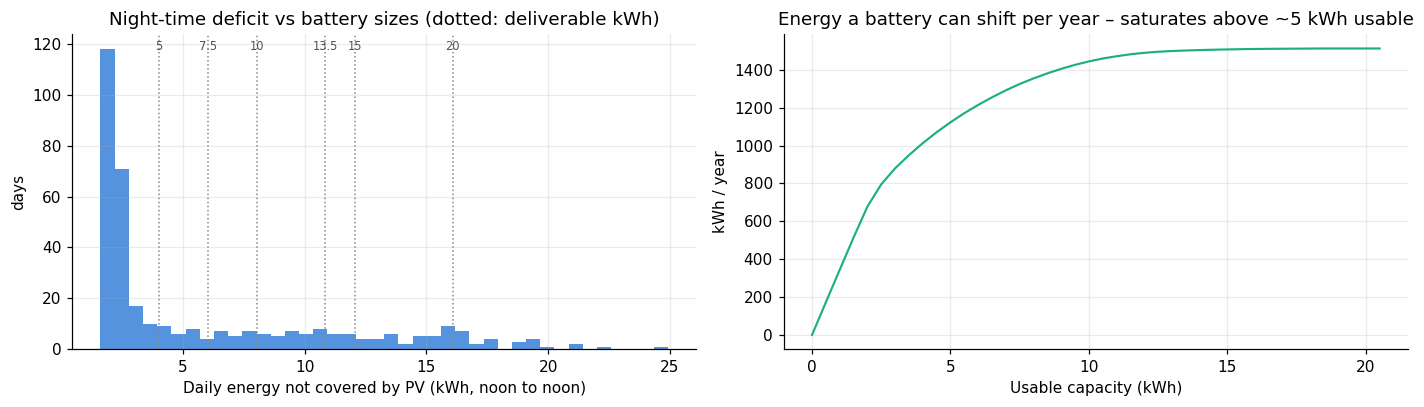

In [17]:
# Sizing from load vs generation: the energy a battery can usefully shift each day is limited by
# (a) the night-time deficit, (b) the usable capacity and (c) the PV surplus available to charge it.
ds = df.loc["2023"]
win = (ds.index - pd.Timedelta(hours=12)).date                      # noon-to-noon window = evening + night + morning
deficit = ((ds.load - ds.pv).clip(lower=0) * DT).groupby(win).sum()     # load not covered by PV
surplus = ((ds.pv - ds.load).clip(lower=0) * DT).groupby((ds.index - pd.Timedelta(hours=12)).date).sum()
eta_rt = Battery().eta_c * Battery().eta_d
caps = np.arange(0, 21, 0.5)
shift = [np.minimum.reduce([deficit.values, np.full(len(deficit), u * Battery().eta_d), surplus.values * eta_rt]).sum() for u in caps]
cover = pd.DataFrame({"Usable (kWh)": [round(0.85 * e, 2) for e in [5, 7.5, 10, 13.5, 15, 20]]},
                     index=["5", "7.5", "10", "13.5", "15", "20"])
cover["Nights fully covered (%)"] = [100 * (deficit <= u * Battery().eta_d).mean() for u in cover["Usable (kWh)"]]
cover["Shiftable energy (kWh/yr)"] = [np.minimum.reduce([deficit.values, np.full(len(deficit), u * Battery().eta_d), surplus.values * eta_rt]).sum() for u in cover["Usable (kWh)"]]
cover["Marginal kWh/yr per extra usable kWh"] = cover["Shiftable energy (kWh/yr)"].diff() / cover["Usable (kWh)"].diff()
cover.index.name = "Nameplate (kWh)"
print(f"Noon-to-noon deficit (2023): mean {deficit.mean():.1f}, P50 {deficit.median():.1f}, P90 {deficit.quantile(.9):.1f} kWh")
display(cover.round(1))

# Report Figure 3
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].hist(deficit, bins=40, color=C["blue"], alpha=0.8)
for u, nm in zip(cover["Usable (kWh)"], cover.index):
    axes[0].axvline(u * Battery().eta_d, color=C["grey"], ls=":", lw=1)
    axes[0].text(u * Battery().eta_d, axes[0].get_ylim()[1] * 0.95, nm, fontsize=7.5, ha="center", color="#52514e")
axes[0].set_xlabel("Daily energy not covered by PV (kWh, noon to noon)"); axes[0].set_ylabel("days")
axes[0].set_title("Night-time deficit vs battery sizes (dotted: deliverable kWh)")
axes[1].plot(caps, shift, color=C["aqua"])
axes[1].set_xlabel("Usable capacity (kWh)"); axes[1].set_ylabel("kWh / year")
axes[1].set_title("Energy a battery can shift per year – saturates above ~5 kWh usable")
plt.tight_layout(); plt.show()

In [18]:
DISC, LIFE = 0.05, 10
ANNUITY = (1 - (1 + DISC) ** -LIFE) / DISC
REBATE_PER_KWH = 370
def capex(e_nom): return 2000 + 850 * e_nom

def econ(savings, bat, rebate=False):
    cost = capex(bat.e_nom) - (REBATE_PER_KWH * bat.usable if rebate else 0)
    return pd.Series({"Capex ($)": cost, "Annual saving ($)": savings,
                      "Simple payback (yr)": cost / savings if savings > 0 else np.inf,
                      f"NPV {LIFE}y @{DISC:.0%} ($)": savings * ANNUITY - cost})

D23 = df.loc["2023"].copy(); D23["pv_act"] = D23["pv"]
print(f"Annuity factor: {ANNUITY:.2f}")

Annuity factor: 7.72


In [19]:
CANDIDATES = [Battery("5 kWh / 2.5 kW", 5.0, 2.5), Battery("7.5 kWh / 3.3 kW", 7.5, 3.3),
              Battery("10 kWh / 5 kW", 10.0, 5.0), Battery("13.5 kWh / 5 kW", 13.5, 5.0),
              Battery("15 kWh / 6 kW", 15.0, 6.0), Battery("20 kWh / 7 kW", 20.0, 7.0)]
pi_flat, pe_flat = D23.imp_flat.values, D23.exp_flat.values
pi_tou, pe_tou = D23.imp_tou.values, D23.exp_tou.values
base_flat = evaluate(no_bess(D23), D23, pi_flat, pe_flat, label="No BESS")
base_tou = evaluate(no_bess(D23), D23, pi_tou, pe_tou, label="No BESS")
pi_ws, pe_ws = retail_prices(D23.spot.values, D23.net.values)
base_ws = evaluate(no_bess(D23), D23, pi_ws, pe_ws, label="No BESS")

rows = []
t0 = time.time()
for b in CANDIDATES:
    for tname, pi, pe, base, fee in [("Flat", pi_flat, pe_flat, base_flat, 0), ("ToU", pi_tou, pe_tou, base_tou, 0),
                                     ("Wholesale", pi_ws, pe_ws, base_ws, VPP_FEE)]:
        r = optimise_year(D23, pi, pe, b)
        ev = evaluate(r, D23, pi, pe, b, fixed_monthly=fee)
        sav = base["Annual bill ($)"] - ev["Annual bill ($)"]
        e1, e2 = econ(sav, b), econ(sav, b, rebate=True)
        rows.append({"Battery": b.name, "Tariff": tname, "Usable (kWh)": b.usable,
                     "Annual bill ($)": ev["Annual bill ($)"], "Saving ($/yr)": sav,
                     "Cycles/yr": ev["Equiv. full cycles"], "Capex ($)": e1["Capex ($)"],
                     "Payback (yr)": e1["Simple payback (yr)"], "Payback w/ rebate (yr)": e2["Simple payback (yr)"],
                     "NPV ($)": e1.iloc[3], "NPV w/ rebate ($)": e2.iloc[3]})
sizing = pd.DataFrame(rows)   # Report Table 4
print(f"solved {len(rows)} full-year optimisations in {time.time()-t0:.0f}s")
sizing.round(1)

solved 18 full-year optimisations in 165s


,Battery,Tariff,Usable (kWh),Annual bill ($),Saving ($/yr),Cycles/yr,Capex ($),Payback (yr),Payback w/ rebate (yr),NPV ($),NPV w/ rebate ($)
0,5 kWh / 2.5 kW,Flat,4.200,-73.300,253.300,244.100,"6,250.000",24.700,18.500,"-4,293.800","-2,721.300"
1,5 kWh / 2.5 kW,ToU,4.200,-162.000,262.600,255.500,"6,250.000",23.800,17.800,"-4,222.400","-2,649.900"
2,5 kWh / 2.5 kW,Wholesale,4.200,132.900,412.000,360.700,"6,250.000",15.200,11.400,"-3,068.900","-1,496.400"
3,7.5 kWh / 3.3 kW,Flat,6.400,-121.400,301.400,193.600,"8,375.000",27.800,20.000,"-6,047.600","-3,688.800"
4,7.5 kWh / 3.3 kW,ToU,6.400,-211.900,312.500,206.600,"8,375.000",26.800,19.300,"-5,961.900","-3,603.100"
5,7.5 kWh / 3.3 kW,Wholesale,6.400,1.200,543.700,334.000,"8,375.000",15.400,11.100,"-4,176.900","-1,818.100"
6,10 kWh / 5 kW,Flat,8.500,-154.700,334.700,161.200,"10,500.000",31.400,22.000,"-7,915.600","-4,770.600"
7,10 kWh / 5 kW,ToU,8.500,-237.300,338.000,171.100,"10,500.000",31.100,21.800,"-7,890.400","-4,745.400"
8,10 kWh / 5 kW,Wholesale,8.500,-142.100,687.000,322.500,"10,500.000",15.300,10.700,"-5,195.200","-2,050.200"
9,13.5 kWh / 5 kW,Flat,11.500,-183.600,363.600,129.700,"13,475.000",37.100,25.400,"-10,667.400","-6,421.600"


In [20]:
best_npv = sizing.loc[sizing.groupby("Tariff")["NPV w/ rebate ($)"].idxmax(), ["Tariff", "Battery", "Saving ($/yr)", "NPV w/ rebate ($)", "Payback w/ rebate (yr)"]]
print("Best NPV per tariff (with rebate):"); display(best_npv.round(1))
best_name = best_npv.set_index("Tariff").loc["Wholesale", "Battery"]
BAT = replace(next(b for b in CANDIDATES if b.name == best_name))
print("Selected:", BAT)

Best NPV per tariff (with rebate):


,Tariff,Battery,Saving ($/yr),NPV w/ rebate ($),Payback w/ rebate (yr)
0,Flat,5 kWh / 2.5 kW,253.300,"-2,721.300",18.500
1,ToU,5 kWh / 2.5 kW,262.600,"-2,649.900",17.800
2,Wholesale,5 kWh / 2.5 kW,412.000,"-1,496.400",11.400


Selected: Battery(name='5 kWh / 2.5 kW', e_nom=5.0, p_max=2.5, soc_min=0.1, soc_max=0.95, eta_c=0.94575, eta_d=0.94575, c_deg=0.04, soc0=0.5, capex=None)


In [21]:
# Commercial product matching the selected configuration (AC-coupled retrofit to the existing PV inverter)
PRODUCT = pd.Series({
    "Battery": "BYD Battery-Box Premium HVS 5.1 (LFP, 2 modules, CEC-listed, 10-year warranty)",
    "Battery inverter": "SMA Sunny Boy Storage 2.5 (AC-coupled, 2.5 kW rated, 97 % max efficiency)",
    "Compatibility": "Listed on BYD HVS/HVM compatible inverter list (SBS 2.5 with 2-4 HVS modules)",
    "Datasheet usable energy (DC)": "5.12 kWh",
    "Datasheet DC round-trip efficiency": ">= 96 %",
    "Modelled nameplate / usable (10-95 % SoC)": f"{BAT.e_nom:.2f} kWh / {BAT.usable:.2f} kWh (conservative)",
    "Modelled power": f"{BAT.p_max} kW charge and discharge (= SBS 2.5 rating)",
    "Modelled efficiency": f"{BAT.eta_c:.4f} each way; AC round trip {BAT.eta_c*BAT.eta_d*100:.1f} % "
                           f"(cells {ETA['cell_bms']**2*100:.1f} % DC + two inverter conversions)",
})
display(PRODUCT.to_frame("Value"))

,Value
Battery,"BYD Battery-Box Premium HVS 5.1 (LFP, 2 module..."
Battery inverter,"SMA Sunny Boy Storage 2.5 (AC-coupled, 2.5 kW ..."
Compatibility,Listed on BYD HVS/HVM compatible inverter list...
Datasheet usable energy (DC),5.12 kWh
Datasheet DC round-trip efficiency,>= 96 %
Modelled nameplate / usable (10-95 % SoC),5.00 kWh / 4.25 kWh (conservative)
Modelled power,2.5 kW charge and discharge (= SBS 2.5 rating)
Modelled efficiency,0.9457 each way; AC round trip 89.4 % (cells 9...


## 2.4 BESS operation and optimisation under different tariffs

### 2.4.1 Flat-rate tariff

In [22]:
res_flat = {
    "No BESS": no_bess(D23),
    "BESS – self-consumption rule": self_consumption_rule(D23, BAT),
    "BESS – optimised (LP)": optimise_year(D23, pi_flat, pe_flat, BAT),
}
tab_flat = pd.DataFrame([evaluate(r, D23, pi_flat, pe_flat, None if k == "No BESS" else BAT, label=k) for k, r in res_flat.items()])
tab_flat["Saving vs no BESS ($)"] = tab_flat.loc["No BESS", "Annual bill ($)"] - tab_flat["Annual bill ($)"]
tab_flat.T.round(1)

,No BESS,BESS – self-consumption rule,BESS – optimised (LP)
Import (kWh),"2,174.000","1,136.600","1,136.600"
Export (kWh),"9,443.500","8,283.200","8,285.800"
Curtailed (kWh),0.000,0.000,0.000
Self-consumption (%),19.700,29.500,29.500
Self-sufficiency (%),51.500,74.700,74.700
Import cost ($),652.200,341.000,341.000
Export revenue ($),472.200,414.200,414.300
Fees ($),0.000,0.000,0.000
Annual bill ($),180.000,-73.200,-73.300
Battery discharge (kWh),0.000,"1,037.400","1,037.400"


In [23]:
print("Physics checks (LP):"); display(check_solution(res_flat["BESS – optimised (LP)"], D23, BAT))
print("Physics checks (rule):"); display(check_solution(res_flat["BESS – self-consumption rule"], D23, BAT))

Physics checks (LP):


max |power balance error| (kW)     0.000
max |SoC recon error| (kWh)        0.000
SoC within limits                   True
charge within derated limit         True
simultaneous ch&dis (intervals)        0
simultaneous imp&exp (intervals)       0
PV used <= PV                       True
dtype: object

Physics checks (rule):


max |power balance error| (kW)     0.000
max |SoC recon error| (kWh)        0.000
SoC within limits                   True
charge within derated limit         True
simultaneous ch&dis (intervals)        0
simultaneous imp&exp (intervals)       0
PV used <= PV                       True
dtype: object

### 2.4.2 Time-of-Use tariff

In [24]:
res_tou = {
    "No BESS": no_bess(D23),
    "BESS – self-consumption rule": self_consumption_rule(D23, BAT),
    "BESS – optimised (LP, grid charging allowed)": optimise_year(D23, pi_tou, pe_tou, BAT),
}
tab_tou = pd.DataFrame([evaluate(r, D23, pi_tou, pe_tou, None if k == "No BESS" else BAT, label=k) for k, r in res_tou.items()])
tab_tou["Saving vs no BESS ($)"] = tab_tou.loc["No BESS", "Annual bill ($)"] - tab_tou["Annual bill ($)"]
display(tab_tou.T.round(1))
display(check_solution(res_tou["BESS – optimised (LP, grid charging allowed)"], D23, BAT))

,No BESS,BESS – self-consumption rule,"BESS – optimised (LP, grid charging allowed)"
Import (kWh),"2,174.000","1,136.600","1,142.300"
Export (kWh),"9,443.500","8,283.200","8,285.800"
Curtailed (kWh),0.000,0.000,0.000
Self-consumption (%),19.700,29.500,29.500
Self-sufficiency (%),51.500,74.700,75.700
Import cost ($),572.800,287.600,252.300
Export revenue ($),472.200,414.200,414.300
Fees ($),0.000,0.000,0.000
Annual bill ($),100.600,-126.500,-162.000
Battery discharge (kWh),0.000,"1,037.400","1,085.800"


max |power balance error| (kW)     0.000
max |SoC recon error| (kWh)        0.000
SoC within limits                   True
charge within derated limit         True
simultaneous ch&dis (intervals)        0
simultaneous imp&exp (intervals)       0
PV used <= PV                       True
dtype: object

### 2.4.3 Wholesale pass-through tariff (incl. curtailment at negative prices, $25/month VPP fee)

In [25]:
res_ws = {
    "No BESS": no_bess(D23),
    "No BESS + curtail at negative prices": no_bess(D23, curtail_price=pe_ws),
    "BESS – self-consumption rule": self_consumption_rule(D23, BAT),
    "BESS – optimised (LP) + VPP fee": optimise_year(D23, pi_ws, pe_ws, BAT),
}
fees = {k: (VPP_FEE if "optimised" in k else 0.0) for k in res_ws}
tab_ws = pd.DataFrame([evaluate(r, D23, pi_ws, pe_ws, None if k.startswith("No BESS") else BAT,
                                fixed_monthly=fees[k], label=k) for k, r in res_ws.items()])
tab_ws["Saving vs no BESS ($)"] = tab_ws.loc["No BESS", "Annual bill ($)"] - tab_ws["Annual bill ($)"]
display(tab_ws.T.round(1))
display(check_solution(res_ws["BESS – optimised (LP) + VPP fee"], D23, BAT))

,No BESS,No BESS + curtail at negative prices,BESS – self-consumption rule,BESS – optimised (LP) + VPP fee
Import (kWh),"2,174.000","2,174.000","1,136.600","1,697.000"
Export (kWh),"9,443.500","4,433.100","8,283.200","4,542.600"
Curtailed (kWh),0.000,"5,010.400",0.000,"4,245.100"
Self-consumption (%),19.700,19.700,29.500,25.300
Self-sufficiency (%),51.500,51.500,74.700,70.400
Import cost ($),514.200,514.200,230.300,219.300
Export revenue ($),-30.600,258.100,-60.700,386.400
Fees ($),0.000,0.000,0.000,300.000
Annual bill ($),544.800,256.100,291.000,132.900
Battery discharge (kWh),0.000,0.000,"1,037.400","1,533.100"


max |power balance error| (kW)     0.000
max |SoC recon error| (kWh)        0.000
SoC within limits                   True
charge within derated limit         True
simultaneous ch&dis (intervals)        0
simultaneous imp&exp (intervals)       0
PV used <= PV                       True
dtype: object

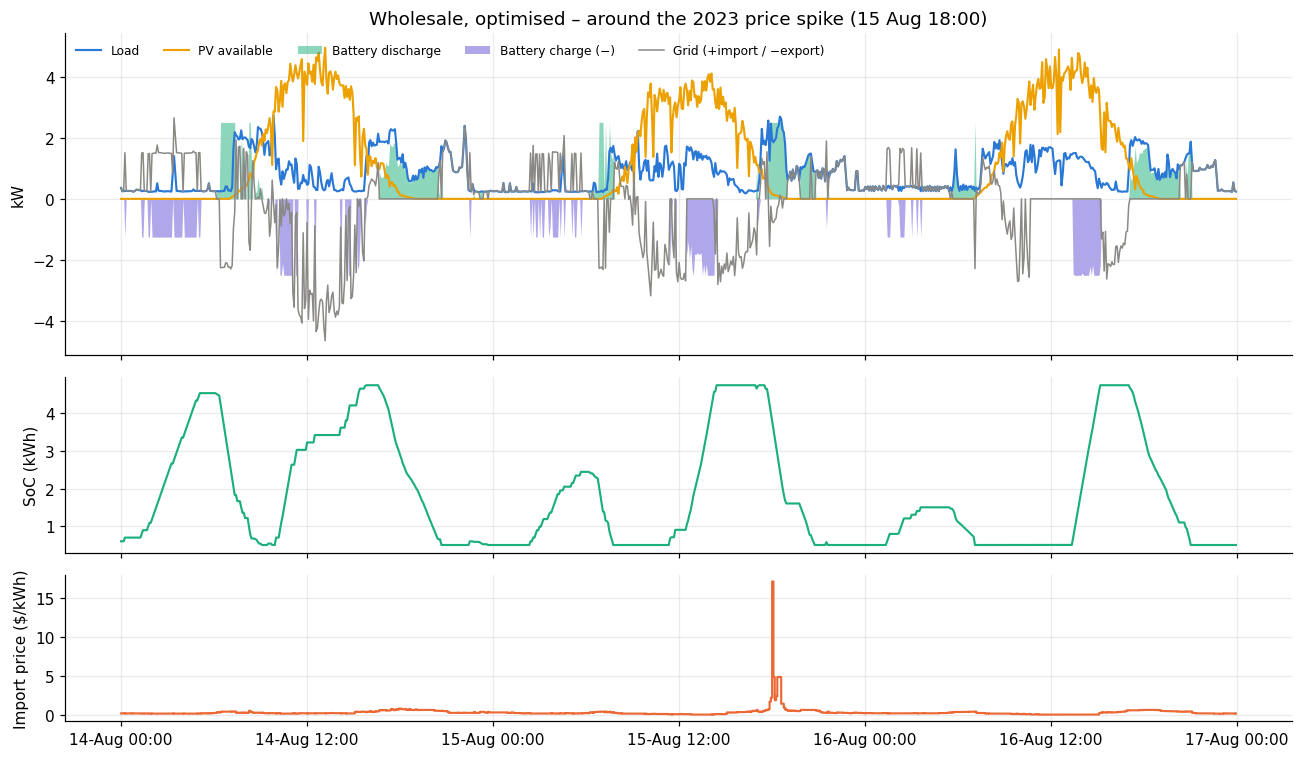

,Export revenue in spike intervals (spot>30c),Export revenue other,Import cost
No BESS,12.200,-42.900,514.200
No BESS + curtail at negative prices,12.200,245.900,514.200
BESS – self-consumption rule,11.600,-72.200,230.300
BESS – optimised (LP) + VPP fee,71.800,314.600,219.300


In [26]:
opt_ws = res_ws["BESS – optimised (LP) + VPP fee"]
# Report Figure 5: the highest-price day of 2023
spike_day = D23.spot.idxmax().normalize() - pd.Timedelta(days=1)
plot_days(opt_ws, D23, spike_day, 3, pd.Series(pi_ws, D23.index), f"Wholesale, optimised – around the 2023 price spike ({D23.spot.idxmax():%d %b %H:%M})")

# value decomposition: where does the money come from?
spk = pe_ws > 0.30
dec = pd.DataFrame({
    "Export revenue in spike intervals (spot>30c)": [(r.exp.values[spk] * pe_ws[spk]).sum() * DT for r in res_ws.values()],
    "Export revenue other": [(r.exp.values[~spk] * pe_ws[~spk]).sum() * DT for r in res_ws.values()],
    "Import cost": [(r.imp.values * pi_ws).sum() * DT for r in res_ws.values()],
}, index=res_ws.keys())
dec.round(1)

## 2.5 Optimisation results with forecasts vs perfect foresight (2024)

### 2.5.1 PV forecast model – trained on 2023, forecast 2024, compared with the commercial forecast

In [27]:
from sklearn.ensemble import HistGradientBoostingRegressor

def solar_elevation(ts):
    t = ts - pd.Timedelta(minutes=2.5)                        # interval midpoint
    doy = t.dayofyear.values; hr = t.hour.values + t.minute.values / 60
    g = 2 * np.pi / 365 * (doy - 1 + (hr - 12) / 24)
    decl = 0.006918 - 0.399912*np.cos(g) + 0.070257*np.sin(g) - 0.006758*np.cos(2*g) + 0.000907*np.sin(2*g)
    eqt = 229.18 * (0.000075 + 0.001868*np.cos(g) - 0.032077*np.sin(g) - 0.014615*np.cos(2*g) - 0.040849*np.sin(2*g))
    solar_time = hr * 60 + eqt + 4 * LON - 60 * 10              # AEST = UTC+10
    ha = np.radians(solar_time / 4 - 180)
    lat = np.radians(LAT)
    cosz = np.sin(lat) * np.sin(decl) + np.cos(lat) * np.cos(decl) * np.cos(ha)
    return np.degrees(np.arcsin(np.clip(cosz, -1, 1)))

def features(d):
    elev = solar_elevation(d.index)
    hr = d.index.hour + d.index.minute / 60; doy = d.index.dayofyear
    return pd.DataFrame({"irr": d.irr.values, "temp": d.temp.values, "elev": elev,
                         "hs": np.sin(2*np.pi*hr/24), "hc": np.cos(2*np.pi*hr/24),
                         "ds": np.sin(2*np.pi*doy/365), "dc": np.cos(2*np.pi*doy/365)}, index=d.index)

GAMMA, NOCT = -0.004, 45
def phys_shape(d):
    tc = d.temp.values + d.irr.values * (NOCT - 20) / 800
    return d.irr.values / 1000 * (1 + GAMMA * (tc - 25))

def fit_phys(d):
    x, y = phys_shape(d), d.pv.values
    return float(x @ y / (x @ x))

def fit_ml(d):
    m = HistGradientBoostingRegressor(max_iter=400, learning_rate=0.05, max_leaf_nodes=31, min_samples_leaf=50, random_state=0)
    m.fit(features(d), d.pv.values); return m

def metrics(y, yhat, cap, day_mask=None):
    e = yhat - y
    m = day_mask if day_mask is not None else np.ones(len(y), bool)
    rmse = np.sqrt(np.mean(e[m] ** 2))
    return pd.Series({"MAE (kW)": np.mean(np.abs(e[m])), "RMSE (kW)": rmse, "MBE (kW)": np.mean(e[m]),
                      "nRMSE (% of capacity)": 100 * rmse / cap, "nRMSE (% of mean daytime PV)": 100 * rmse / np.mean(y[m]),
                      "Daily-energy MAE (kWh)": np.nan})

train = df.loc["2023"].copy()
CAP = train.pv.quantile(0.999)
cv_pred = pd.DataFrame(index=train.index, columns=["phys", "ml"], dtype=float)
for mth in range(1, 13):
    te = train.index.month == mth
    k = fit_phys(train[~te]); cv_pred.loc[te, "phys"] = k * phys_shape(train[te])
    cv_pred.loc[te, "ml"] = np.clip(fit_ml(train[~te]).predict(features(train[te])), 0, None)
cv_pred["phys"] = cv_pred["phys"].clip(lower=0)
day = train.irr.values > 0
cv_tab = {}
for m_ in ["phys", "ml"]:
    s_ = metrics(train.pv.values, cv_pred[m_].values, CAP, day)
    s_["Daily-energy MAE (kWh)"] = ((cv_pred[m_] - train.pv).resample("D").sum() * DT).abs().mean()
    cv_tab[{"phys": "Physical", "ml": "Gradient boosting"}[m_]] = s_
print(f"Reference capacity for nRMSE: {CAP:.2f} kW")
pd.DataFrame(cv_tab).T.round(3)

Reference capacity for nRMSE: 8.35 kW


,MAE (kW),RMSE (kW),MBE (kW),nRMSE (% of capacity),nRMSE (% of mean daytime PV),Daily-energy MAE (kWh)
Physical,0.268,0.522,0.031,6.256,21.735,0.717
Gradient boosting,0.266,0.518,-0.006,6.202,21.548,0.445


In [28]:
# Final models trained on all of 2023 -> forecast 2024 from 2024 weather
D24 = df.loc["2024"].copy()
k_phys = fit_phys(train); ml = fit_ml(train)
D24["pv_phys"] = np.clip(k_phys * phys_shape(D24), 0, None)
D24["pv_ml"] = np.clip(ml.predict(features(D24)), 0, None)
D24["pv_act"] = D24["pv_comm"]                   # commercial forecast treated as actual (per brief)
print(f"Fitted k (effective kWp x PR): {k_phys:.2f}")
day24 = D24.irr.values > 0
tab24 = {}
for col, name in [("pv_phys", "Physical model"), ("pv_ml", "Gradient boosting")]:
    s_ = metrics(D24.pv_act.values, D24[col].values, CAP, day24)
    s_["Daily-energy MAE (kWh)"] = ((D24[col] - D24.pv_act).resample("D").sum() * DT).abs().mean()
    tab24[name] = s_
print("Report Table 6 – 2024: our forecasts vs commercial forecast (daylight intervals)")
display(pd.DataFrame(tab24).T.round(3))
print("Annual PV 2024 (kWh): commercial", round(D24.pv_act.sum()*DT), "| physical", round(D24.pv_phys.sum()*DT), "| GB", round(D24.pv_ml.sum()*DT))

Fitted k (effective kWp x PR): 7.33
Report Table 6 – 2024: our forecasts vs commercial forecast (daylight intervals)


,MAE (kW),RMSE (kW),MBE (kW),nRMSE (% of capacity),nRMSE (% of mean daytime PV),Daily-energy MAE (kWh)
Physical model,0.086,0.162,-0.044,1.935,6.210,0.914
Gradient boosting,0.089,0.147,-0.080,1.759,5.646,1.090


Annual PV 2024 (kWh): commercial 12789 | physical 12571 | GB 12418


In [29]:
best_pv = "pv_ml" if cv_tab["Gradient boosting"]["RMSE (kW)"] < cv_tab["Physical"]["RMSE (kW)"] else "pv_phys"
D24["pv_fc"] = D24[best_pv]
print("PV forecast used in scheduler:", best_pv)

PV forecast used in scheduler: pv_ml


### 2.5.2 Wholesale price forecast

In [30]:
SPOT_ALL = df["spot"].values          # 2023 provided + 2024 AEMO; index-aligned with df
TOD_ALL = (df.index.hour * 12 + df.index.minute // 5).values

def price_forecast(i, H, D=14, decay=12, series=SPOT_ALL):
    # Forecast of intervals i..i+H-1 using information up to i-1 only.
    hist_start = max(0, i - D * STEPS_PER_DAY)
    hist = series[hist_start:i]
    tod_hist = TOD_ALL[hist_start:i]
    prof = pd.Series(hist).groupby(tod_hist).median().reindex(range(288)).ffill().bfill().values
    last = np.median(series[max(0, i - 3):i]) if i > 0 else prof[0]
    h = np.arange(1, H + 1)
    w = np.exp(-h / decay)
    return w * last + (1 - w) * prof[TOD_ALL[i:i + H]]

def eval_price_fc(issue_idx, H=576, **kw):
    errs = np.zeros(H); cnt = 0
    for i in issue_idx:
        if i + H > len(SPOT_ALL): continue
        errs += np.abs(price_forecast(i, H, **kw) - SPOT_ALL[i:i + H]); cnt += 1
    return errs / cnt

n23 = (df.index.year == 2023).sum()
issues23 = np.arange(14 * 288, n23 - 576, 72)         # every 6 h in 2023
grid = []
for D_ in [3, 7, 14, 28]:
    for H_ in [3, 12, 36, 144]:
        grid.append({"D (days)": D_, "decay H (steps)": H_, "MAE 0-48h ($/kWh)": eval_price_fc(issues23, D=D_, decay=H_).mean()})
grid = pd.DataFrame(grid).sort_values("MAE 0-48h ($/kWh)")
PF_D, PF_H = int(grid.iloc[0]["D (days)"]), int(grid.iloc[0]["decay H (steps)"])
print(f"Selected D={PF_D} days, H={PF_H} steps"); display(grid.head(6))

Selected D=14 days, H=36 steps


,D (days),decay H (steps),MAE 0-48h ($/kWh)
10,14,36,0.046
9,14,12,0.047
6,7,36,0.047
14,28,36,0.047
8,14,3,0.047
5,7,12,0.047


In [31]:
issues24 = np.arange(n23, len(df) - 576, 72)
mae_model = eval_price_fc(issues24, D=PF_D, decay=PF_H)
mae_prof = eval_price_fc(issues24, D=PF_D, decay=1e-9)    # profile only
mae_pers = np.zeros(576); c_ = 0
for i in issues24:
    mae_pers += np.abs(SPOT_ALL[i - 1] - SPOT_ALL[i:i + 576]); c_ += 1
mae_pers /= c_
price_tab = pd.Series({"Persistence (latest price held constant)": mae_pers.mean(),
                       f"Profile ({PF_D}-day median at same time of day)": mae_prof.mean(),
                       "Blend of both (used)": mae_model.mean()}, name="MAE 0-48 h ($/kWh)")
print("Report Table 7 – 2024 out-of-sample price forecast error (48-hour horizon):")
display(price_tab.round(3).to_frame())

Report Table 7 – 2024 out-of-sample price forecast error (48-hour horizon):


,MAE 0-48 h ($/kWh)
Persistence (latest price held constant),0.110
Profile (14-day median at same time of day),0.062
Blend of both (used),0.061


### 2.5.3 48-hour rolling-horizon scheduler (hourly re-plan, 5-minute execution)

In [32]:
def block_dt(H, fine=24, block=6):
    # Durations and index map for a multi-resolution horizon.
    n_fine = min(H, fine)
    rest = H - n_fine
    groups = [np.array([k]) for k in range(n_fine)]
    for s in range(n_fine, H, block):
        groups.append(np.arange(s, min(H, s + block)))
    dt = np.array([len(g) * DT for g in groups])
    return groups, dt

def agg(x, groups): return np.array([x[g].mean() for g in groups])

def run_mpc(data, pv_plan, spot_plan_fn, bat, H=576, replan=12, rt=False, spike=0.30, spot_hist_last=None):
    # data: DataFrame with load, pv_act, temp, spot, net (actuals). pv_plan: array; spot_plan_fn(i,H)->array
    n = len(data)
    load, pv_act, spot = data.load.values, data.pv_act.values, data.spot.values
    tou = data.net.values      # network charge ($/kWh)
    ch_lim = charge_derate(data.temp.values)
    pi_act, pe_act = retail_prices(spot, tou)
    out = {k: np.zeros(n) for k in ["imp", "exp", "ch", "dis", "pv_used", "soc"]}
    soc = bat.soc0 * bat.e_nom
    for i in range(0, n, replan):
        Hh = min(H, n - i)
        groups, dt = block_dt(Hh)
        sp_fc = spot_plan_fn(i, Hh)
        pi_fc, pe_fc = retail_prices(sp_fc, tou[i:i + Hh])
        L_, PV_ = load[i:i + Hh], pv_plan[i:i + Hh]
        r = solve_lp(agg(L_, groups), agg(PV_, groups), agg(pi_fc, groups), agg(pe_fc, groups),
                     np.array([ch_lim[i:i + Hh][g].min() for g in groups]), bat, soc, dt=dt)
        for j in range(min(replan, Hh)):        # execute the first hour (fine-resolution steps)
            t = i + j
            ch, dis = r["ch"][j], r["dis"][j]
            net_b = dis - ch                              # one inverter: net the set-point
            ch, dis = max(-net_b, 0.0), max(net_b, 0.0)
            last = spot[t - 1] if t > 0 else (spot_hist_last if spot_hist_last is not None else 0.0)
            if rt and last > spike:                       # real-time override: spike in progress -> discharge
                ch, dis = 0.0, bat.p_max
            # keep SoC feasible numerically
            ch = min(ch, max(0.0, (bat.e_max - soc) / (bat.eta_c * DT)))
            dis = min(dis, max(0.0, (soc - bat.e_min) * bat.eta_d / DT))
            if rt:   # curtail on the last *known* 5-min price (prices are strongly autocorrelated)
                curtail = last < 0
            else:    # curtail if the hourly plan expected a negative export price
                curtail = r["pv_used"][j] < PV_[j] - 1e-4 and pe_fc[j] < 0
            pv_u = min(pv_act[t], max(0.0, load[t] + ch - dis)) if curtail else pv_act[t]
            soc = soc + ch * bat.eta_c * DT - dis / bat.eta_d * DT
            g = load[t] + ch - dis - pv_u
            out["imp"][t], out["exp"][t] = max(g, 0), max(-g, 0)
            out["ch"][t], out["dis"][t], out["pv_used"][t], out["soc"][t] = ch, dis, pv_u, soc
    return pd.DataFrame(out, index=data.index)

def cached(name, fn):
    fp = f"{CACHE_DIR}/{name}.pkl"
    if os.path.exists(fp):
        return pd.read_pickle(fp)
    t0 = time.time(); res = fn(); res.to_pickle(fp)
    print(f"{name}: {time.time()-t0:.0f}s"); return res

off24 = n23   # offset of 2024 in df arrays
perfect_price = lambda i, H: SPOT_ALL[off24 + i: off24 + i + H]
fc_price = lambda i, H: price_forecast(off24 + i, H, D=PF_D, decay=PF_H)
pv_true, pv_fc = D24.pv_act.values, D24.pv_fc.values

# quick sanity test on one week before the full runs
wk = D24.loc["2024-02-01":"2024-02-07"]
_t = time.time(); _r = run_mpc(wk, wk.pv_act.values, lambda i, H: wk.spot.values[i:i+H], BAT)
print(f"one week MPC: {time.time()-_t:.1f}s"); display(check_solution(_r, wk, BAT))

one week MPC: 1.2s


max |power balance error| (kW)     0.000
max |SoC recon error| (kWh)        0.000
SoC within limits                   True
charge within derated limit         True
simultaneous ch&dis (intervals)        0
simultaneous imp&exp (intervals)       0
PV used <= PV                       True
dtype: object

In [33]:
TARIFF_TAG = "ausnetNAST11"   # change when the price build-up changes, so stale caches are not reused
CACHE_TAG = f"{BAT.e_nom}_{BAT.p_max}_{BAT.c_deg}_{PF_D}_{PF_H}_{best_pv}_{TARIFF_TAG}"
mpc = {
    "A. Perfect foresight": cached(f"mpc_A_{CACHE_TAG}", lambda: run_mpc(D24, pv_true, perfect_price, BAT)),
    "B. PV uncertainty only": cached(f"mpc_B_{CACHE_TAG}", lambda: run_mpc(D24, pv_fc, perfect_price, BAT)),
    "C. Price uncertainty only": cached(f"mpc_C_{CACHE_TAG}", lambda: run_mpc(D24, pv_true, fc_price, BAT)),
    "D. Both uncertain (realistic)": cached(f"mpc_D_{CACHE_TAG}", lambda: run_mpc(D24, pv_fc, fc_price, BAT)),
}

### 2.5.4 Forecasts vs perfect foresight – which uncertainty matters more

In [34]:
pi24, pe24 = retail_prices(D24.spot.values, D24.net.values)
res24 = {
    "No BESS": no_bess(D24),
    "BESS – self-consumption rule": self_consumption_rule(D24, BAT),
    **mpc,
}
rows = []
for k, r in res24.items():
    fee = 0.0 if (k.startswith("No BESS") or "rule" in k) else VPP_FEE
    rows.append(evaluate(r, D24, pi24, pe24, None if k == "No BESS" else BAT, fixed_monthly=fee, label=k))
tab24 = pd.DataFrame(rows)   # Report Table 8
tab24["Saving vs no BESS ($)"] = tab24.loc["No BESS", "Annual bill ($)"] - tab24["Annual bill ($)"]
pf_gain = tab24.loc["A. Perfect foresight", "Saving vs no BESS ($)"]
tab24["% of perfect-foresight saving"] = 100 * tab24["Saving vs no BESS ($)"] / pf_gain
display(tab24[["Annual bill ($)", "Saving vs no BESS ($)", "% of perfect-foresight saving", "Import (kWh)", "Export (kWh)",
               "Curtailed (kWh)", "Self-consumption (%)", "Self-sufficiency (%)", "Equiv. full cycles"]].round(1))
display(check_solution(mpc["D. Both uncertain (realistic)"], D24, BAT))

,Annual bill ($),Saving vs no BESS ($),% of perfect-foresight saving,Import (kWh),Export (kWh),Curtailed (kWh),Self-consumption (%),Self-sufficiency (%),Equiv. full cycles
No BESS,460.200,0.000,0.000,"2,122.300","10,415.900",0.000,18.600,52.800,0.000
BESS – self-consumption rule,188.600,271.700,42.700,"1,077.400","9,247.100",0.000,27.700,76.000,245.900
A. Perfect foresight,-175.700,636.000,100.000,"1,411.300","4,614.700","4,903.200",25.600,74.200,376.900
B. PV uncertainty only,-173.000,633.300,99.600,"1,426.000","4,641.100","4,892.100",25.500,73.900,375.800
C. Price uncertainty only,143.400,316.800,49.800,"1,393.200","3,833.100","5,719.900",25.300,72.900,270.900
D. Both uncertain (realistic),145.800,314.500,49.400,"1,408.700","3,854.900","5,714.400",25.200,72.600,269.300


max |power balance error| (kW)     0.000
max |SoC recon error| (kWh)        0.000
SoC within limits                   True
charge within derated limit         True
simultaneous ch&dis (intervals)        0
simultaneous imp&exp (intervals)       0
PV used <= PV                       True
dtype: object

Cost of PV forecast error    : $3/yr
Cost of price forecast error : $319/yr
Cost of both                 : $321/yr
Extra PV curtailed with forecasts (D vs A): 811 kWh


Spike-interval value: perfect foresight $375 vs realistic (D) $170 -> gap $205 (64% of total forecast-error cost)
Feb + Aug share of realistic (D) loss: 57%


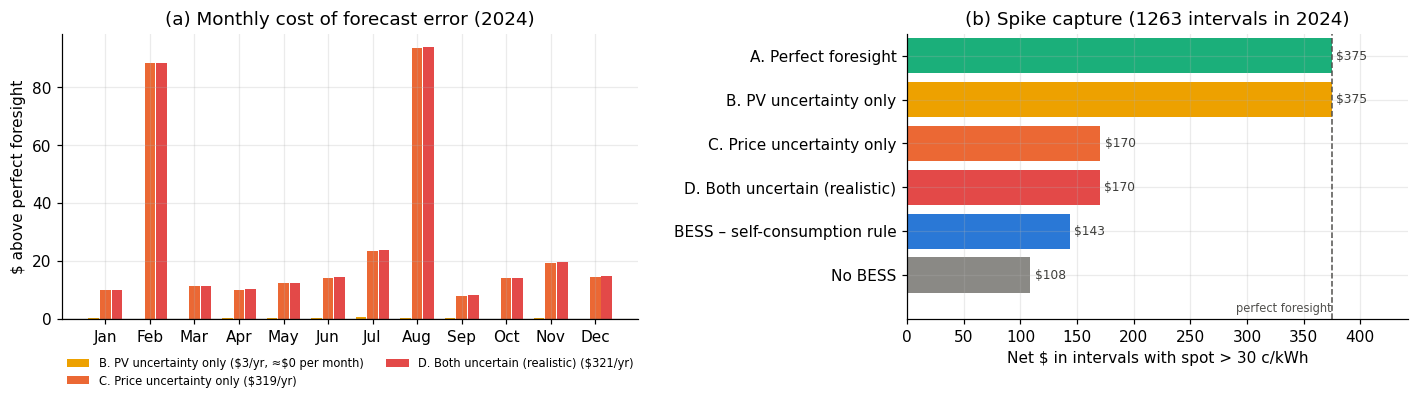

In [35]:
lossB = tab24.loc["B. PV uncertainty only", "Annual bill ($)"] - tab24.loc["A. Perfect foresight", "Annual bill ($)"]
lossC = tab24.loc["C. Price uncertainty only", "Annual bill ($)"] - tab24.loc["A. Perfect foresight", "Annual bill ($)"]
lossD = tab24.loc["D. Both uncertain (realistic)", "Annual bill ($)"] - tab24.loc["A. Perfect foresight", "Annual bill ($)"]
print(f"Cost of PV forecast error    : ${lossB:,.0f}/yr")
print(f"Cost of price forecast error : ${lossC:,.0f}/yr")
print(f"Cost of both                 : ${lossD:,.0f}/yr")
print(f"Extra PV curtailed with forecasts (D vs A): {tab24.loc['D. Both uncertain (realistic)', 'Curtailed (kWh)'] - tab24.loc['A. Perfect foresight', 'Curtailed (kWh)']:,.0f} kWh")

# where is the price-uncertainty loss incurred? monthly bill difference
mb = pd.DataFrame({k: (r.imp * pi24 - r.exp * pe24).resample("ME").sum() * DT for k, r in mpc.items()})
diff = mb.sub(mb["A. Perfect foresight"], axis=0).drop(columns="A. Perfect foresight")
# Report Figure 6
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw=dict(width_ratios=[1.15, 1]))
x = np.arange(len(diff)); w = 0.26
for i, (c_, col) in enumerate(zip(diff.columns, [C["yellow"], C["orange"], C["red"]])):
    tot = diff[c_].sum()
    lab = f"{c_} (\\${tot:,.0f}/yr" + (", ≈\\$0 per month)" if abs(tot) < 20 else ")")
    axes[0].bar(x + (i - 1) * w, diff[c_], w - 0.02, color=col, label=lab)
axes[0].set_xticks(x, diff.index.strftime("%b")); axes[0].axhline(0, color="#52514e", lw=0.8)
axes[0].set_ylabel("$ above perfect foresight"); axes[0].set_title("(a) Monthly cost of forecast error (2024)")
axes[0].legend(fontsize=7.5, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.1))
# value captured in high-price intervals
spk24 = D24.spot.values > 0.30
cap = {k: (r.exp.values[spk24] * pe24[spk24]).sum() * DT - (r.imp.values[spk24] * pi24[spk24]).sum() * DT for k, r in res24.items()}
cap = pd.Series(cap).sort_values()
cmap = {"No BESS": C["grey"], "BESS – self-consumption rule": C["blue"], "A. Perfect foresight": C["aqua"],
        "B. PV uncertainty only": C["yellow"], "C. Price uncertainty only": C["orange"],
        "D. Both uncertain (realistic)": C["red"]}
axes[1].barh(cap.index, cap.values, color=[cmap[k] for k in cap.index])
for yi, v in enumerate(cap.values):
    axes[1].text(v + 4, yi, f"\\${v:,.0f}", va="center", fontsize=8, color="#3d3d3a")
pf_cap = cap["A. Perfect foresight"]
axes[1].axvline(pf_cap, color="#52514e", ls="--", lw=1)
axes[1].text(pf_cap, -0.9, "perfect foresight", ha="right", va="bottom", fontsize=7.5, color="#52514e")
axes[1].set_xlim(0, pf_cap * 1.18); axes[1].set_ylim(-1, len(cap) - 0.5)
axes[1].set_xlabel("Net $ in intervals with spot > 30 c/kWh")
axes[1].set_title(f"(b) Spike capture ({spk24.sum()} intervals in 2024)")
print("Spike-interval value: perfect foresight $%.0f vs realistic (D) $%.0f -> gap $%.0f (%.0f%% of total forecast-error cost)"
      % (pf_cap, cap["D. Both uncertain (realistic)"], pf_cap - cap["D. Both uncertain (realistic)"],
         100 * (pf_cap - cap["D. Both uncertain (realistic)"]) / lossD))
print("Feb + Aug share of realistic (D) loss: %.0f%%" % (100 * diff.loc[diff.index.month.isin([2, 8]), "D. Both uncertain (realistic)"].sum() / lossD))
plt.tight_layout(); plt.show()

# Step 3 – Metrics

## 3.1 Annual bill and self-consumption

Annual bill ($)  \
Tariff                      Operation                                              
Flat (2023, PF)             No BESS                                      180.000   
                            Self-consumption rule                        -73.200   
                            Optimised (LP)                               -73.300   
ToU (2023, PF)              No BESS                                      100.600   
                            Self-consumption rule                       -126.500   
                            Optimised (LP)                              -162.000   
Wholesale (2023, PF)        No BESS                                      544.800   
                            No BESS + curtailment                        256.100   
                            Self-consumption rule                        291.000   
                            Optimised (LP) + VPP fee                     132.900   
Wholesale (2024, forecasts) No BESS                                      460.200   
                            Self-consumption rule                        188.600   
                            Optimised – perfect foresight (MPC)         -175.700   
                            Optimised – forecasts (MPC)                  145.800   

                                                                 Import (kWh)  \
Tariff                      Operation                                           
Flat (2023, PF)             No BESS                                 2,174.000   
                            Self-consumption rule                   1,136.600   
                            Optimised (LP)                          1,136.600   
ToU (2023, PF)              No BESS                                 2,174.000   
                            Self-consumption rule                   1,136.600   
                            Optimised (LP)                          1,142.300   
Wholesale (2023, PF)        No BESS                                 2,174.000   
                            No BESS + curtailment                   2,174.000   
                            Self-consumption rule                   1,136.600   
                            Optimised (LP) + VPP fee                1,697.000   
Wholesale (2024, forecasts) No BESS                                 2,122.300   
                            Self-consumption rule                   1,077.400   
                            Optimised – perfect foresight (MPC)     1,411.300   
                            Optimised – forecasts (MPC)             1,408.700   

                                                                 Export (kWh)  \
Tariff                      Operation                                           
Flat (2023, PF)             No BESS                                 9,443.500   
                            Self-consumption rule                   8,283.200   
                            Optimised (LP)                          8,285.800   
ToU (2023, PF)              No BESS                                 9,443.500   
                            Self-consumption rule                   8,283.200   
                            Optimised (LP)                          8,285.800   
Wholesale (2023, PF)        No BESS                                 9,443.500   
                            No BESS + curtailment                   4,433.100   
                            Self-consumption rule                   8,283.200   
                            Optimised (LP) + VPP fee                4,542.600   
Wholesale (2024, forecasts) No BESS                                10,415.900   
                            Self-consumption rule                   9,247.100   
                            Optimised – perfect foresight (MPC)     4,614.700   
                            Optimised – forecasts (MPC)             3,854.900   

                                                                 Curtailed (kWh)  \
Tariff                      Operation     

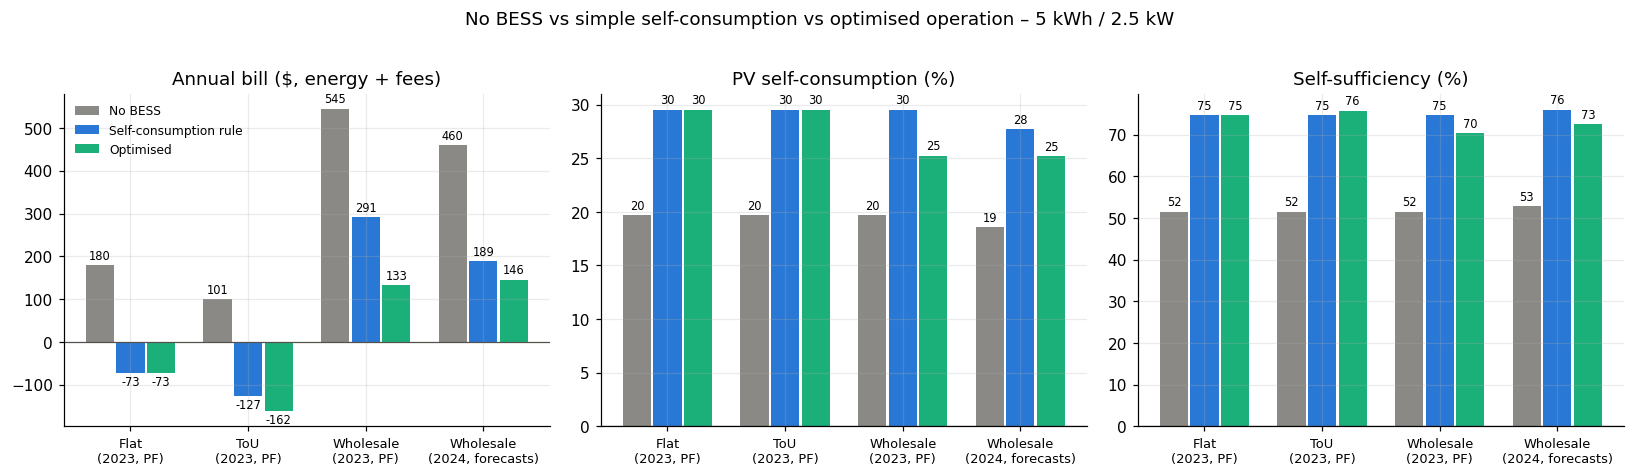

In [36]:
COLS = ["Annual bill ($)", "Import (kWh)", "Export (kWh)", "Curtailed (kWh)", "Self-consumption (%)",
        "Self-sufficiency (%)", "Battery discharge (kWh)", "Equiv. full cycles", "Fees ($)"]
blocks = [
    ("Flat (2023, PF)", tab_flat, {"No BESS": "No BESS", "BESS – self-consumption rule": "Self-consumption rule",
                                   "BESS – optimised (LP)": "Optimised (LP)"}),
    ("ToU (2023, PF)", tab_tou, {"No BESS": "No BESS", "BESS – self-consumption rule": "Self-consumption rule",
                                 "BESS – optimised (LP, grid charging allowed)": "Optimised (LP)"}),
    ("Wholesale (2023, PF)", tab_ws, {"No BESS": "No BESS", "No BESS + curtail at negative prices": "No BESS + curtailment",
                                      "BESS – self-consumption rule": "Self-consumption rule",
                                      "BESS – optimised (LP) + VPP fee": "Optimised (LP) + VPP fee"}),
    ("Wholesale (2024, forecasts)", tab24, {"No BESS": "No BESS", "BESS – self-consumption rule": "Self-consumption rule",
                                            "A. Perfect foresight": "Optimised – perfect foresight (MPC)",
                                            "D. Both uncertain (realistic)": "Optimised – forecasts (MPC)"}),
]
parts = []
for tariff, tab, names in blocks:
    t = tab.loc[list(names), COLS].rename(index=names)
    t["Saving vs no BESS ($)"] = t.loc["No BESS", "Annual bill ($)"] - t["Annual bill ($)"]
    t["Saving vs self-consumption rule ($)"] = t.loc["Self-consumption rule", "Annual bill ($)"] - t["Annual bill ($)"]
    t.index = pd.MultiIndex.from_product([[tariff], t.index], names=["Tariff", "Operation"])
    parts.append(t)
performance = pd.concat(parts)   # Report Table 5 (2023 rows)
display(performance.round(1))

# Report Figure 4
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
tariffs = [b[0] for b in blocks]
x = np.arange(len(tariffs)); w = 0.26
ops = [("No BESS", C["grey"]), ("Self-consumption rule", C["blue"]), ("optimised", C["aqua"])]
def pick(tariff, op, col):
    sub = performance.loc[tariff]
    row = op if op in sub.index else [i for i in sub.index if i.startswith("Optimised")][-1]
    return sub.loc[row, col]
for ax, col, title in [(axes[0], "Annual bill ($)", "Annual bill ($, energy + fees)"),
                       (axes[1], "Self-consumption (%)", "PV self-consumption (%)"),
                       (axes[2], "Self-sufficiency (%)", "Self-sufficiency (%)")]:
    for i, (op, colr) in enumerate(ops):
        vals = [pick(t, op, col) for t in tariffs]
        bars = ax.bar(x + (i - 1) * w, vals, w - 0.02, color=colr, label="Optimised" if op == "optimised" else op)
        ax.bar_label(bars, fmt="%.0f", fontsize=7.5, padding=2)
    ax.set_xticks(x, [t.replace(" (", "\n(") for t in tariffs], fontsize=8.5); ax.set_title(title)
    ax.axhline(0, color="#52514e", lw=0.8)
axes[0].legend(fontsize=8)
plt.suptitle(f"No BESS vs simple self-consumption vs optimised operation – {BAT.name}", y=1.02)
plt.tight_layout(); plt.show()

## 3.2 Savings against different operations

In [37]:
sav_tab = performance[["Annual bill ($)", "Saving vs no BESS ($)", "Saving vs self-consumption rule ($)"]].copy()
display(sav_tab.round(1))

Annual bill ($)  \
Tariff                      Operation                                              
Flat (2023, PF)             No BESS                                      180.000   
                            Self-consumption rule                        -73.200   
                            Optimised (LP)                               -73.300   
ToU (2023, PF)              No BESS                                      100.600   
                            Self-consumption rule                       -126.500   
                            Optimised (LP)                              -162.000   
Wholesale (2023, PF)        No BESS                                      544.800   
                            No BESS + curtailment                        256.100   
                            Self-consumption rule                        291.000   
                            Optimised (LP) + VPP fee                     132.900   
Wholesale (2024, forecasts) No BESS                                      460.200   
                            Self-consumption rule                        188.600   
                            Optimised – perfect foresight (MPC)         -175.700   
                            Optimised – forecasts (MPC)                  145.800   

                                                                 Saving vs no BESS ($)  \
Tariff                      Operation                                                    
Flat (2023, PF)             No BESS                                              0.000   
                            Self-consumption rule                              253.200   
                            Optimised (LP)                                     253.300   
ToU (2023, PF)              No BESS                                              0.000   
                            Self-consumption rule                              227.100   
                            Optimised (LP)                                     262.600   
Wholesale (2023, PF)        No BESS                                              0.000   
                            No BESS + curtailment                              288.700   
                            Self-consumption rule                              253.900   
                            Optimised (LP) + VPP fee                           412.000   
Wholesale (2024, forecasts) No BESS                                              0.000   
                            Self-consumption rule                              271.700   
                            Optimised – perfect foresight (MPC)                636.000   
                            Optimised – forecasts (MPC)                        314.500   

                                                                 Saving vs self-consumption rule ($)  
Tariff                      Operation                                                                 
Flat (2023, PF)             No BESS                                                         -253.200  
                            Self-consumption rule                                              0.000  
                            Optimised (LP)                                                     0.100  
ToU (2023, PF)              No BESS                                                         -227.100  
                            Self-consumption rule                                              0.000  
                            Optimised (LP)                                                    35.400  
Wholesale (2023, PF)        No BESS                                                         -253.900  
                            No BESS + curtailment                                             34.900  
                            Self-consumption rule                                              0.000  
                            Optimised (LP) + VPP fee                                         158.100  
Wholesale (2024, forecasts) No BESS        

## 3.3 Payback time and techno-economic analysis of the system

In [38]:
# 2024 flat / ToU bills (rule-based, no fee) so every tariff option is compared on the same year
alt24 = {}
for tname, pi, pe in [("Flat", D24.imp_flat.values, D24.exp_flat.values), ("ToU", D24.imp_tou.values, D24.exp_tou.values)]:
    alt24[(tname, "No BESS")] = evaluate(no_bess(D24), D24, pi, pe)["Annual bill ($)"]
    alt24[(tname, "Self-consumption rule")] = evaluate(self_consumption_rule(D24, BAT), D24, pi, pe, BAT)["Annual bill ($)"]
    alt24[(tname, "Optimised (LP)")] = evaluate(optimise_year(D24, pi, pe, BAT), D24, pi, pe, BAT)["Annual bill ($)"]

status_quo23 = tab_flat.loc["No BESS", "Annual bill ($)"]
options = [
    ("Flat + self-consumption rule (2023)", tab_flat, "BESS – self-consumption rule", "No BESS"),
    ("ToU + optimised (2023)", tab_tou, "BESS – optimised (LP, grid charging allowed)", "No BESS"),
    ("Wholesale + VPP optimisation (2023, perfect foresight)", tab_ws, "BESS – optimised (LP) + VPP fee", "No BESS"),
    ("Wholesale + VPP optimisation (2024, forecasts)", tab24, "D. Both uncertain (realistic)", "No BESS"),
]
rows = []
for name, tab, op, base in options:
    bill, base_bill = tab.loc[op, "Annual bill ($)"], tab.loc[base, "Annual bill ($)"]
    sav = base_bill - bill
    wear = tab.loc[op, "Degradation cost ($)"]
    e0, e1 = econ(sav, BAT), econ(sav, BAT, rebate=True)
    rows.append({"Option": name, "Annual bill ($)": bill, "Saving vs no BESS, same tariff ($/yr)": sav,
                 "Battery wear at $0.04/kWh ($/yr)": wear, "Cycles/yr": tab.loc[op, "Equiv. full cycles"],
                 "Payback (yr)": e0["Simple payback (yr)"], "Payback w/ rebate (yr)": e1["Simple payback (yr)"],
                 f"NPV {LIFE}y w/ rebate ($)": e1.iloc[3]})
te = pd.DataFrame(rows).set_index("Option")   # Report Table 9
print(f"Battery: {BAT.name}; capex ${capex(BAT.e_nom):,.0f} (${capex(BAT.e_nom) - REBATE_PER_KWH*BAT.usable:,.0f} after rebate)")
display(te.round(1))
print("2024 bills for the non-wholesale options ($):", {f"{k[0]} – {k[1]}": round(v, 1) for k, v in alt24.items()})

# Break-even installed cost: $/kWh (plus $2,000 fixed) at which payback with rebate equals the 10-year life
for name, tab, op, base in options[2:]:
    sav = tab.loc[base, "Annual bill ($)"] - tab.loc[op, "Annual bill ($)"]
    c_be = (LIFE * sav - 2000 + REBATE_PER_KWH * BAT.usable) / BAT.e_nom
    print(f"{name}: payback < {LIFE} yr only if installed cost < ${c_be:,.0f}/kWh (base case $850/kWh)")
print(f"Cycles over {LIFE} years (wholesale + VPP, 2023): {tab_ws.loc['BESS – optimised (LP) + VPP fee', 'Equiv. full cycles'] * LIFE:,.0f} vs 6,000-cycle rating")

Battery: 5 kWh / 2.5 kW; capex $6,250 ($4,678 after rebate)


,Annual bill ($),"Saving vs no BESS, same tariff ($/yr)",Battery wear at $0.04/kWh ($/yr),Cycles/yr,Payback (yr),Payback w/ rebate (yr),NPV 10y w/ rebate ($)
Option,,,,,,,
Flat + self-consumption rule (2023),-73.200,253.200,87.900,244.100,24.700,18.500,"-2,722.300"
ToU + optimised (2023),-162.000,262.600,91.900,255.500,23.800,17.800,"-2,649.900"
"Wholesale + VPP optimisation (2023, perfect foresight)",132.900,412.000,129.800,360.700,15.200,11.400,"-1,496.400"
"Wholesale + VPP optimisation (2024, forecasts)",145.800,314.500,96.900,269.300,19.900,14.900,"-2,249.300"


2024 bills for the non-wholesale options ($): {'Flat – No BESS': np.float64(115.9), 'Flat – Self-consumption rule': np.float64(-139.1), 'Flat – Optimised (LP)': np.float64(-139.3), 'ToU – No BESS': np.float64(38.9), 'ToU – Self-consumption rule': np.float64(-190.1), 'ToU – Optimised (LP)': np.float64(-223.5)}
Wholesale + VPP optimisation (2023, perfect foresight): payback < 10 yr only if installed cost < $738/kWh (base case $850/kWh)
Wholesale + VPP optimisation (2024, forecasts): payback < 10 yr only if installed cost < $543/kWh (base case $850/kWh)
Cycles over 10 years (wholesale + VPP, 2023): 3,607 vs 6,000-cycle rating


## 3.4 Value of and cost to the customer of the VPP optimisation service

,Gross value of optimisation ($/yr),VPP fee ($/yr),Net to customer ($/yr),Extra battery wear ($/yr),Net incl. extra wear ($/yr),Break-even fee ($/month),Extra cycles/yr
Case,,,,,,,
2023 – perfect foresight,458.100,300.000,158.100,41.900,116.200,38.200,116.600
2024 – perfect foresight,664.300,300.000,364.300,47.100,317.200,55.400,131.100
2024 – forecasts (realistic),342.800,300.000,42.800,8.300,34.500,28.600,23.500


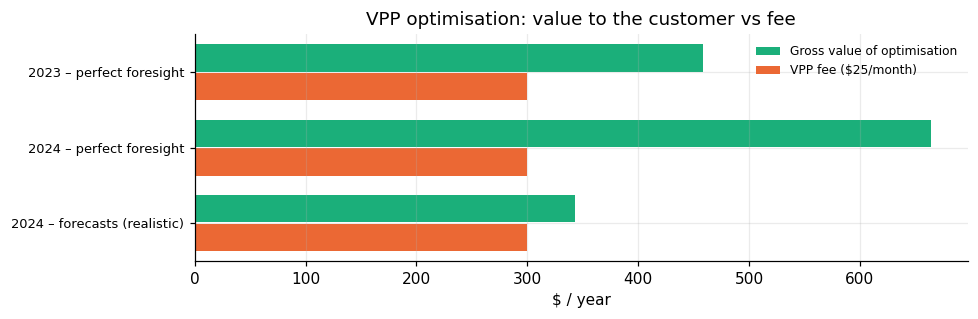

In [39]:
# Value of the VPP service = what optimisation adds on top of owning the same battery with simple self-consumption.
def vpp_row(label, tab, rule, opt):
    fee = tab.loc[opt, "Fees ($)"]
    gross = tab.loc[rule, "Annual bill ($)"] - (tab.loc[opt, "Annual bill ($)"] - fee)
    wear = tab.loc[opt, "Degradation cost ($)"] - tab.loc[rule, "Degradation cost ($)"]
    return {"Case": label, "Gross value of optimisation ($/yr)": gross, "VPP fee ($/yr)": fee,
            "Net to customer ($/yr)": gross - fee, "Extra battery wear ($/yr)": wear,
            "Net incl. extra wear ($/yr)": gross - fee - wear, "Break-even fee ($/month)": gross / 12,
            "Extra cycles/yr": tab.loc[opt, "Equiv. full cycles"] - tab.loc[rule, "Equiv. full cycles"]}
vpp = pd.DataFrame([
    vpp_row("2023 – perfect foresight", tab_ws, "BESS – self-consumption rule", "BESS – optimised (LP) + VPP fee"),
    vpp_row("2024 – perfect foresight", tab24, "BESS – self-consumption rule", "A. Perfect foresight"),
    vpp_row("2024 – forecasts (realistic)", tab24, "BESS – self-consumption rule", "D. Both uncertain (realistic)"),
]).set_index("Case")   # Report Table 10
display(vpp.round(1))

# Report Figure 7
fig, ax = plt.subplots(figsize=(9, 3.0))
y = np.arange(len(vpp)); h = 0.38
ax.barh(y - h / 2, vpp["Gross value of optimisation ($/yr)"], h - 0.02, color=C["aqua"], label="Gross value of optimisation")
ax.barh(y + h / 2, vpp["VPP fee ($/yr)"], h - 0.02, color=C["orange"], label="VPP fee ($25/month)")
ax.set_yticks(y, vpp.index, fontsize=8.5); ax.invert_yaxis(); ax.set_xlabel("$ / year")
ax.set_title("VPP optimisation: value to the customer vs fee"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 3.5 Revenue analysis and comparison across scenarios

In [40]:
# Where the value comes from (2023, perfect foresight): curtailment alone vs full optimisation
no_b, no_b_curt = tab_ws.loc["No BESS", "Annual bill ($)"], tab_ws.loc["No BESS + curtail at negative prices", "Annual bill ($)"]
rule_b = tab_ws.loc["BESS – self-consumption rule", "Annual bill ($)"]
opt_b = tab_ws.loc["BESS – optimised (LP) + VPP fee", "Annual bill ($)"] - VPP_FEE * 12
print(f"2023 wholesale – curtailment alone (no battery) saves ${no_b - no_b_curt:,.0f}/yr; "
      f"battery with simple rule saves ${no_b - rule_b:,.0f}/yr; optimisation (before fee) saves ${no_b - opt_b:,.0f}/yr")

# Customer's best choice per year (lowest bill incl. fees) with the same battery
best = pd.DataFrame({
    "2023 (perfect foresight)": {"Flat + battery (rule)": tab_flat.loc["BESS – self-consumption rule", "Annual bill ($)"],
                                 "ToU + battery (optimised)": tab_tou.loc["BESS – optimised (LP, grid charging allowed)", "Annual bill ($)"],
                                 "Wholesale + battery (rule, no VPP)": tab_ws.loc["BESS – self-consumption rule", "Annual bill ($)"],
                                 "Wholesale + VPP": tab_ws.loc["BESS – optimised (LP) + VPP fee", "Annual bill ($)"]},
    "2024 (forecasts)": {"Flat + battery (rule)": alt24[("Flat", "Self-consumption rule")],
                         "ToU + battery (optimised)": alt24[("ToU", "Optimised (LP)")],
                         "Wholesale + battery (rule, no VPP)": tab24.loc["BESS – self-consumption rule", "Annual bill ($)"],
                         "Wholesale + VPP": tab24.loc["D. Both uncertain (realistic)", "Annual bill ($)"]},
})
print("Annual bill by product with the same battery ($, incl. VPP fee where applicable):")
display(best.round(0))

# Report Table 11 – bill breakdown (export revenue shown as a negative cost)
cols_ = {"ToU + optimised battery (2023)": (tab_tou, "BESS – optimised (LP, grid charging allowed)"),
         "Wholesale, no battery (2023)": (tab_ws, "No BESS"),
         "Wholesale + VPP (2023, perfect foresight)": (tab_ws, "BESS – optimised (LP) + VPP fee"),
         "Wholesale + VPP (2024, forecasts)": (tab24, "D. Both uncertain (realistic)")}
breakdown = pd.DataFrame({k: {"Import cost": t.loc[o, "Import cost ($)"], "Export revenue": -t.loc[o, "Export revenue ($)"],
                              "Energy bill (before VPP fee)": t.loc[o, "Annual bill ($)"] - t.loc[o, "Fees ($)"],
                              "VPP fee": t.loc[o, "Fees ($)"], "Annual bill": t.loc[o, "Annual bill ($)"]}
                          for k, (t, o) in cols_.items()})
display(breakdown.round(0))
print(f"ToU + optimised battery, 2024 energy bill: ${alt24[('ToU', 'Optimised (LP)')]:,.0f}")
print(f"2023 no-battery exports: {tab_ws.loc['No BESS', 'Export (kWh)']:,.0f} kWh, worth "
      f"${tab_ws.loc['No BESS', 'Export revenue ($)']:,.0f} at wholesale vs ${tab_flat.loc['No BESS', 'Export revenue ($)']:,.0f} at the 5 c feed-in tariff")

2023 wholesale – curtailment alone (no battery) saves $289/yr; battery with simple rule saves $254/yr; optimisation (before fee) saves $712/yr
Annual bill by product with the same battery ($, incl. VPP fee where applicable):


,2023 (perfect foresight),2024 (forecasts)
Flat + battery (rule),-73.000,-139.000
ToU + battery (optimised),-162.000,-223.000
"Wholesale + battery (rule, no VPP)",291.000,189.000
Wholesale + VPP,133.000,146.000


,ToU + optimised battery (2023),"Wholesale, no battery (2023)","Wholesale + VPP (2023, perfect foresight)","Wholesale + VPP (2024, forecasts)"
Import cost,252.000,514.000,219.000,365.000
Export revenue,-414.000,31.000,-386.000,-519.000
Energy bill (before VPP fee),-162.000,545.000,-167.000,-154.000
VPP fee,0.000,0.000,300.000,300.000
Annual bill,-162.000,545.000,133.000,146.000


ToU + optimised battery, 2024 energy bill: $-223
2023 no-battery exports: 9,443 kWh, worth $-31 at wholesale vs $472 at the 5 c feed-in tariff


## Modelling limitations (not modelled)
- Only the AC-coupled retrofit topology is modelled (existing PV inverter kept).
- Temperature derating applies to cold-weather charging only; no high-temperature or discharge derating.
- Degradation cost is linear per kWh of throughput ($0.04/kWh each way); depth-of-discharge effects and calendar ageing are ignored.